# 07 — Definitive Robustness Evaluation and Critical Analysis

## Robustness-Enhanced Vision-Language-Action Learning for Generalizable Robotic Manipulation

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Frozen final training budget:** inherited from Notebook 05b  
**Final model registry:** frozen by Notebook 06

---

## Notebook objective

Training and hyperparameter selection are finished.

Notebook 07 performs the **definitive closed-loop robustness experiment** on the frozen eight-checkpoint model registry created by Notebook 06.

The central research question is:

> **At the same empirically frozen training budget, does combined language + environmental robustness training (M2-LE) improve closed-loop generalization relative to standard fine-tuning (M1)?**

This notebook is intentionally evaluation-heavy. It produces the final evidence required for:

- task-success comparison,
- held-out language transfer,
- held-out visual-category transfer,
- combined-shift robustness,
- ID/OOD trade-off analysis,
- component ablations,
- uncertainty quantification,
- paired statistical evidence,
- failure analysis,
- report-ready figures and tables.

### Hard scientific boundary

No checkpoint may be replaced, retrained, extended, or selected after observing results in this notebook.

Notebook 04 is retained as a **pilot diagnostic evaluation**.  
Notebook 07 is the **definitive evaluation** used for final research claims.

## 1. Predeclared hypotheses and interpretation rules

### Research questions

- **RQ1:** Does robustness-oriented fine-tuning improve manipulation success under distribution shift?
- **RQ2:** How does linguistic variation from L0→L1→L2→held-out L3 affect performance, and does language-aware training help?
- **RQ3:** How strongly do seen-family photometric and held-out sensor-noise perturbations affect performance?
- **RQ4:** Does robustness training transfer to perturbation categories never used in training?
- **RQ5:** Is improved robustness associated with a meaningful ID-performance trade-off?

### Primary comparison

The confirmatory comparison is:

**M1 vs M2-LE** at matched training seeds:

- 42
- 123
- 2026

under:

- `E0_ID`
- `E1_L3`
- `E2_SEEN_PHOTO`
- `E3_HELDOUT_NOISE`
- `E4_COMBINED`

### Mechanism ablations

At seed 42:

- **M2-L** is compared on L0/L1/L2/L3.
- **M2-E** is compared on E0 / photometric / sensor noise.
- M1 and M2-LE provide matched controls.

### Evidence interpretation

A primary M2-LE advantage is treated as **strong multi-seed support** when:

1. the mean paired success-rate difference is positive;
2. the 95% hierarchical paired-bootstrap CI is entirely above zero;
3. the Holm-adjusted paired McNemar p-value is `< 0.05`;
4. M2-LE improves in at least 2 of 3 matched training seeds.

If the mean effect is positive and seed-consistent but uncertainty crosses zero, it is reported as **directional support**, not proof.

If effects are inconsistent or centered near zero, the conclusion is **no clear advantage**.

No result is relabeled to force a positive hypothesis.

## 2. Definitive evaluation replication

Notebook 04 used 3 replicas per task as a pilot.

Notebook 07 increases the final evaluation to:

\[
10\ tasks \times 5\ replicas = 50\ episodes
\]

for every model-condition cell.

This gives the primary three-seed comparison:

\[
3\ seeds \times 50 = 150\ episodes
\]

per variant and primary condition.

The staged matrix contains **41 unique model-condition cells** and therefore:

\[
41 \times 50 = 2050\ closed\mbox{-}loop\ episodes
\]

This sample size is frozen before the definitive outcomes are observed.

## 3. Environment, paths and Notebook 06 prerequisite

In [1]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from datetime import datetime
import gc
import hashlib
import json
import math
import subprocess
import sys
import time
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LIBERO_SUITE = "libero_spatial"

EPISODES_PER_TASK = 5
BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_SEED = 20260826

PRIMARY_VARIANTS = [
    "M1",
    "M2-LE",
]

PRIMARY_SEEDS = [
    42,
    123,
    2026,
]

PRIMARY_CONDITIONS = [
    "E0_ID",
    "E1_L3",
    "E2_SEEN_PHOTO",
    "E3_HELDOUT_NOISE",
    "E4_COMBINED",
]


def find_repo_root(start: Path) -> Path:
    current = start.resolve()

    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate

    if current.name == "notebooks":
        return current.parent

    return current


REPO_ROOT = find_repo_root(
    Path.cwd()
)

RESULTS_DIR = (
    REPO_ROOT
    / "results"
)

METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
    / "definitive_robustness_evaluation"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
    / "definitive_robustness_evaluation"
)

QUALITATIVE_DIR = (
    RESULTS_DIR
    / "qualitative"
    / "definitive_robustness_evaluation"
)

EXPERIMENT_CONFIG_DIR = (
    REPO_ROOT
    / "configs"
    / "experiments"
)

for directory in [
    METRICS_DIR,
    FIGURES_DIR,
    QUALITATIVE_DIR,
    EXPERIMENT_CONFIG_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            [
                "git",
                "rev-parse",
                "HEAD",
            ],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None


PROJECT_GIT_SHA = git_sha(
    REPO_ROOT
)


NOTEBOOK06_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "validated_final_retraining"
    / "notebook06_summary.json"
)

NOTEBOOK07_HANDOFF_PATH = (
    EXPERIMENT_CONFIG_DIR
    / "notebook07_definitive_evaluation_handoff_v1.json"
)

assert NOTEBOOK06_SUMMARY_PATH.exists(), (
    f"Missing Notebook 06 summary: {NOTEBOOK06_SUMMARY_PATH}"
)

assert NOTEBOOK07_HANDOFF_PATH.exists(), (
    f"Missing Notebook 07 handoff: {NOTEBOOK07_HANDOFF_PATH}"
)


with open(
    NOTEBOOK06_SUMMARY_PATH,
    "r",
) as f:
    notebook06_summary = json.load(
        f
    )


with open(
    NOTEBOOK07_HANDOFF_PATH,
    "r",
) as f:
    evaluation_handoff = json.load(
        f
    )


assert notebook06_summary[
    "technical_status"
] == "PASS"

assert evaluation_handoff[
    "training_budget_frozen"
] is True

assert evaluation_handoff[
    "budget_selection_used_ood_results"
] is False

assert evaluation_handoff[
    "model_selection_after_ood_forbidden"
] is True

assert int(
    evaluation_handoff[
        "final_checkpoint_count"
    ]
) == 8

assert evaluation_handoff[
    "primary_variants"
] == PRIMARY_VARIANTS

assert evaluation_handoff[
    "primary_seeds"
] == PRIMARY_SEEDS


environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "Notebook 06 status": notebook06_summary[
        "technical_status"
    ],
    "final_checkpoint_count": evaluation_handoff[
        "final_checkpoint_count"
    ],
    "final_training_steps": evaluation_handoff[
        "final_training_steps"
    ],
    "episodes_per_task": EPISODES_PER_TASK,
    "primary_seeds": PRIMARY_SEEDS,
}

display(
    pd.DataFrame(
        [environment_summary]
    ).T.rename(
        columns={0: "Value"}
    )
)

assert torch.cuda.is_available(), (
    "Definitive evaluation requires the validated CUDA environment."
)

print("NOTEBOOK 06 + DEFINITIVE EVALUATION HANDOFF: PASS")

,Value
python,3.12.14
torch,2.11.0+cu128
cuda_available,True
device,cuda
gpu,NVIDIA GeForce RTX 5090
project_git_sha,95713d40415a8912f81c434c6b5380f659221c30
Notebook 06 status,PASS
final_checkpoint_count,8
final_training_steps,25000
episodes_per_task,5


NOTEBOOK 06 + DEFINITIVE EVALUATION HANDOFF: PASS


## 4. Load and audit the frozen eight-checkpoint registry

In [2]:
FINAL_MODEL_REGISTRY_PATH = (
    REPO_ROOT
    / evaluation_handoff[
        "final_model_registry"
    ]
)

assert FINAL_MODEL_REGISTRY_PATH.exists()

model_registry_df = pd.read_csv(
    FINAL_MODEL_REGISTRY_PATH
)

required_registry_columns = {
    "variant",
    "seed",
    "role",
    "training_steps",
    "checkpoint",
    "checkpoint_signature",
    "validation_loss",
}

assert required_registry_columns.issubset(
    model_registry_df.columns
)

assert len(
    model_registry_df
) == 8

expected_pairs = {
    ("M1", 42),
    ("M1", 123),
    ("M1", 2026),
    ("M2-L", 42),
    ("M2-E", 42),
    ("M2-LE", 42),
    ("M2-LE", 123),
    ("M2-LE", 2026),
}

observed_pairs = set(
    zip(
        model_registry_df[
            "variant"
        ],
        model_registry_df[
            "seed"
        ].astype(int),
    )
)

assert observed_pairs == expected_pairs

assert (
    model_registry_df[
        "training_steps"
    ].astype(int)
    == int(
        evaluation_handoff[
            "final_training_steps"
        ]
    )
).all()


for row in model_registry_df.itertuples():
    checkpoint = (
        REPO_ROOT
        / str(
            row.checkpoint
        )
    )

    assert checkpoint.exists(), (
        f"Checkpoint missing: {checkpoint}"
    )

    assert (
        checkpoint
        / "config.json"
    ).exists(), (
        f"Checkpoint config missing: {checkpoint}"
    )


model_registry_df = (
    model_registry_df
    .copy()
)

model_registry_df[
    "run_id"
] = [
    (
        f"{variant.replace('-', '')}"
        f"_seed{int(seed)}"
    )
    for variant, seed
    in zip(
        model_registry_df[
            "variant"
        ],
        model_registry_df[
            "seed"
        ],
    )
]

assert not model_registry_df[
    "run_id"
].duplicated().any()


display(
    model_registry_df[
        [
            "run_id",
            "variant",
            "seed",
            "role",
            "training_steps",
            "validation_loss",
            "checkpoint",
        ]
    ]
)

print("FROZEN FINAL MODEL REGISTRY: PASS")

,run_id,variant,seed,role,training_steps,validation_loss,checkpoint
0,M1_seed42,M1,42,primary_control,25000,0.570412,experiments/final_budget_validation/m1_standar...
1,M1_seed123,M1,123,primary_control,25000,0.564678,experiments/final_budget_validation/m1_standar...
2,M1_seed2026,M1,2026,primary_control,25000,0.557629,experiments/final_budget_validation/m1_standar...
3,M2E_seed42,M2-E,42,ablation,25000,0.556888,experiments/validated_final_retraining/m2e_see...
4,M2L_seed42,M2-L,42,ablation,25000,0.589158,experiments/validated_final_retraining/m2l_see...
5,M2LE_seed42,M2-LE,42,primary_proposed,25000,0.581579,experiments/validated_final_retraining/m2le_se...
6,M2LE_seed123,M2-LE,123,primary_proposed,25000,0.557852,experiments/validated_final_retraining/m2le_se...
7,M2LE_seed2026,M2-LE,2026,primary_proposed,25000,0.578886,experiments/validated_final_retraining/m2le_se...


FROZEN FINAL MODEL REGISTRY: PASS


## 5. Load task mapping and frozen language perturbations

In [3]:
TASK_MAPPING_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "dataset_eda"
    / "libero_spatial_dataset_task_mapping.csv"
)

LANGUAGE_TABLE_PATH = (
    REPO_ROOT
    / "configs"
    / "experiments"
    / "libero_spatial_language_augmentations_v1.csv"
)

assert TASK_MAPPING_PATH.exists()
assert LANGUAGE_TABLE_PATH.exists()

task_mapping_df = pd.read_csv(
    TASK_MAPPING_PATH
)

language_df = pd.read_csv(
    LANGUAGE_TABLE_PATH
)

required_mapping_columns = {
    "suite_task_id",
    "dataset_task_index",
    "benchmark_instruction",
}

assert required_mapping_columns.issubset(
    task_mapping_df.columns
)

assert len(
    task_mapping_df
) == 10

assert task_mapping_df[
    "suite_task_id"
].nunique() == 10

assert task_mapping_df[
    "dataset_task_index"
].nunique() == 10

assert len(
    language_df
) == 40

assert set(
    language_df[
        "level"
    ]
) == {
    "L0",
    "L1",
    "L2",
    "L3",
}


suite_to_dataset_task = {
    int(
        row[
            "suite_task_id"
        ]
    ): int(
        row[
            "dataset_task_index"
        ]
    )
    for _, row
    in task_mapping_df.iterrows()
}


language_lookup = {
    (
        int(
            row[
                "task_id"
            ]
        ),
        str(
            row[
                "level"
            ]
        ),
    ): str(
        row[
            "augmented_instruction"
        ]
    )
    for _, row
    in language_df.iterrows()
}


for suite_task_id, dataset_task_id in (
    suite_to_dataset_task.items()
):
    for level in [
        "L0",
        "L1",
        "L2",
        "L3",
    ]:
        assert (
            dataset_task_id,
            level,
        ) in language_lookup


display(
    task_mapping_df[
        [
            "suite_task_id",
            "dataset_task_index",
            "benchmark_instruction",
        ]
    ]
)

print("TASK + LANGUAGE MAPPING: PASS")

,suite_task_id,dataset_task_index,benchmark_instruction
0,0,34,pick up the black bowl between the plate and t...
1,1,37,pick up the black bowl next to the ramekin and...
2,2,38,pick up the black bowl from table center and p...
3,3,35,pick up the black bowl on the cookie box and p...
4,4,31,pick up the black bowl in the top drawer of th...
5,5,32,pick up the black bowl on the ramekin and plac...
6,6,30,pick up the black bowl next to the cookie box ...
7,7,33,pick up the black bowl on the stove and place ...
8,8,36,pick up the black bowl next to the plate and p...
9,9,39,pick up the black bowl on the wooden cabinet a...


TASK + LANGUAGE MAPPING: PASS


## 6. Freeze definitive evaluation conditions

In [4]:
CONDITIONS = {
    "E0_ID": {
        "label": "ID / L0",
        "language_level": "L0",
        "image_shift": "NONE",
        "shift_role": "ID",
    },
    "E1_L1": {
        "label": "Language L1",
        "language_level": "L1",
        "image_shift": "NONE",
        "shift_role": "seen_language",
    },
    "E1_L2": {
        "label": "Language L2",
        "language_level": "L2",
        "image_shift": "NONE",
        "shift_role": "seen_language",
    },
    "E1_L3": {
        "label": "Language L3 held-out",
        "language_level": "L3",
        "image_shift": "NONE",
        "shift_role": "heldout_language",
    },
    "E2_SEEN_PHOTO": {
        "label": "Seen photometric shift",
        "language_level": "L0",
        "image_shift": "SEEN_PHOTO",
        "shift_role": "seen_visual",
    },
    "E3_HELDOUT_NOISE": {
        "label": "Held-out sensor noise",
        "language_level": "L0",
        "image_shift": "HELDOUT_NOISE",
        "shift_role": "heldout_visual",
    },
    "E4_COMBINED": {
        "label": "L3 + photometric",
        "language_level": "L3",
        "image_shift": "SEEN_PHOTO",
        "shift_role": "combined",
    },
}

assert list(
    CONDITIONS.keys()
) == evaluation_handoff[
    "planned_conditions"
]

condition_df = pd.DataFrame(
    [
        {
            "condition_id": condition_id,
            **condition,
        }
        for condition_id, condition
        in CONDITIONS.items()
    ]
)

display(
    condition_df
)

print("DEFINITIVE EVALUATION CONDITIONS: FROZEN")

,condition_id,label,language_level,image_shift,shift_role
0,E0_ID,ID / L0,L0,NONE,ID
1,E1_L1,Language L1,L1,NONE,seen_language
2,E1_L2,Language L2,L2,NONE,seen_language
3,E1_L3,Language L3 held-out,L3,NONE,heldout_language
4,E2_SEEN_PHOTO,Seen photometric shift,L0,SEEN_PHOTO,seen_visual
5,E3_HELDOUT_NOISE,Held-out sensor noise,L0,HELDOUT_NOISE,heldout_visual
6,E4_COMBINED,L3 + photometric,L3,SEEN_PHOTO,combined


DEFINITIVE EVALUATION CONDITIONS: FROZEN


## 7. Freeze the staged evaluation matrix

### Phase A — seed-42 mechanism ablations

- M1: all seven conditions
- M2-L: E0 + L1/L2/L3
- M2-E: E0 + photometric + held-out noise
- M2-LE: all seven conditions

### Phase B — primary three-seed confirmation

Seeds 123 and 2026 are added for M1 and M2-LE on:

- E0
- held-out L3
- seen photometric shift
- held-out sensor noise
- combined L3 + photometric

Seed 42 is already present in Phase A and is reused.

This produces exactly **41 model-condition cells × 50 episodes = 2050 episodes**.

In [5]:
run_lookup = {
    (
        str(
            row[
                "variant"
            ]
        ),
        int(
            row[
                "seed"
            ]
        ),
    ): str(
        row[
            "run_id"
        ]
    )
    for _, row
    in model_registry_df.iterrows()
}


phase_a_conditions = {
    "M1": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
        "E4_COMBINED",
    ],
    "M2-L": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
    ],
    "M2-E": [
        "E0_ID",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
    ],
    "M2-LE": [
        "E0_ID",
        "E1_L1",
        "E1_L2",
        "E1_L3",
        "E2_SEEN_PHOTO",
        "E3_HELDOUT_NOISE",
        "E4_COMBINED",
    ],
}


plan_rows = []


for variant, condition_ids in (
    phase_a_conditions.items()
):
    run_id = run_lookup[
        (
            variant,
            42,
        )
    ]

    for condition_id in condition_ids:
        plan_rows.append({
            "phase": "A_ablation_seed42",
            "run_id": run_id,
            "variant": variant,
            "model_seed": 42,
            "condition_id": condition_id,
        })


for variant in [
    "M1",
    "M2-LE",
]:
    for model_seed in [
        123,
        2026,
    ]:
        run_id = run_lookup[
            (
                variant,
                model_seed,
            )
        ]

        for condition_id in (
            PRIMARY_CONDITIONS
        ):
            plan_rows.append({
                "phase": "B_primary_multiseed",
                "run_id": run_id,
                "variant": variant,
                "model_seed": model_seed,
                "condition_id": condition_id,
            })


evaluation_plan_df = (
    pd.DataFrame(
        plan_rows
    )
    .drop_duplicates(
        subset=[
            "run_id",
            "condition_id",
        ]
    )
    .sort_values(
        [
            "phase",
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
    .reset_index(
        drop=True
    )
)

evaluation_plan_df[
    "task_count"
] = 10

evaluation_plan_df[
    "episodes_per_task"
] = EPISODES_PER_TASK

evaluation_plan_df[
    "episodes"
] = (
    evaluation_plan_df[
        "task_count"
    ]
    * evaluation_plan_df[
        "episodes_per_task"
    ]
)

PLANNED_EPISODES = int(
    evaluation_plan_df[
        "episodes"
    ].sum()
)

assert len(
    evaluation_plan_df
) == 41

assert PLANNED_EPISODES == 2050


display(
    evaluation_plan_df
)

print(
    "Unique model-condition cells:",
    len(
        evaluation_plan_df
    ),
)

print(
    "Episodes per cell:",
    10
    * EPISODES_PER_TASK,
)

print(
    "Total planned episodes:",
    PLANNED_EPISODES,
)

print("DEFINITIVE EVALUATION MATRIX: FROZEN")

,phase,run_id,variant,model_seed,condition_id,task_count,episodes_per_task,episodes
0,A_ablation_seed42,M1_seed42,M1,42,E0_ID,10,5,50
1,A_ablation_seed42,M1_seed42,M1,42,E1_L1,10,5,50
2,A_ablation_seed42,M1_seed42,M1,42,E1_L2,10,5,50
3,A_ablation_seed42,M1_seed42,M1,42,E1_L3,10,5,50
4,A_ablation_seed42,M1_seed42,M1,42,E2_SEEN_PHOTO,10,5,50
5,A_ablation_seed42,M1_seed42,M1,42,E3_HELDOUT_NOISE,10,5,50
6,A_ablation_seed42,M1_seed42,M1,42,E4_COMBINED,10,5,50
7,A_ablation_seed42,M2E_seed42,M2-E,42,E0_ID,10,5,50
8,A_ablation_seed42,M2E_seed42,M2-E,42,E2_SEEN_PHOTO,10,5,50
9,A_ablation_seed42,M2E_seed42,M2-E,42,E3_HELDOUT_NOISE,10,5,50


Unique model-condition cells: 41
Episodes per cell: 50
Total planned episodes: 2050
DEFINITIVE EVALUATION MATRIX: FROZEN


## 8. Freeze the definitive evaluation protocol and cache identity

The cache is intentionally separate from Notebook 04.

A completed episode is reusable only when all of these match:

- definitive protocol SHA256,
- frozen checkpoint signature,
- run/model identity,
- condition,
- task,
- replica.

This prevents pilot results or stale checkpoint results from entering the final analysis.

In [6]:
def canonical_json_hash(
    payload,
):
    encoded = json.dumps(
        payload,
        sort_keys=True,
        separators=(
            ",",
            ":",
        ),
        default=str,
    ).encode(
        "utf-8"
    )

    return hashlib.sha256(
        encoded
    ).hexdigest()


registry_protocol_rows = (
    model_registry_df[
        [
            "run_id",
            "variant",
            "seed",
            "training_steps",
            "checkpoint_signature",
        ]
    ]
    .sort_values(
        "run_id"
    )
    .to_dict(
        orient="records"
    )
)


evaluation_protocol = {
    "protocol_id": (
        "definitive_robustness_evaluation_v1"
    ),
    "source_notebook": (
        "07_definitive_robustness_evaluation"
    ),
    "source_notebook06_summary": str(
        NOTEBOOK06_SUMMARY_PATH.relative_to(
            REPO_ROOT
        )
    ),
    "source_notebook07_handoff": str(
        NOTEBOOK07_HANDOFF_PATH.relative_to(
            REPO_ROOT
        )
    ),
    "episodes_per_task": int(
        EPISODES_PER_TASK
    ),
    "task_count": 10,
    "planned_episodes": int(
        PLANNED_EPISODES
    ),
    "bootstrap_samples": int(
        BOOTSTRAP_SAMPLES
    ),
    "bootstrap_seed": int(
        BOOTSTRAP_SEED
    ),
    "primary_variants": (
        PRIMARY_VARIANTS
    ),
    "primary_seeds": (
        PRIMARY_SEEDS
    ),
    "primary_conditions": (
        PRIMARY_CONDITIONS
    ),
    "conditions": (
        CONDITIONS
    ),
    "model_registry": (
        registry_protocol_rows
    ),
    "evaluation_plan": (
        evaluation_plan_df[
            [
                "phase",
                "run_id",
                "variant",
                "model_seed",
                "condition_id",
            ]
        ].to_dict(
            orient="records"
        )
    ),
    "episode_seed_formula": (
        "100000 + suite_task_id*100 + replica"
    ),
    "heldout_sensor_noise_sigma": 0.05,
    "seen_photometric_shift": {
        "brightness": 0.85,
        "contrast": 1.15,
        "saturation": 0.85,
    },
    "checkpoint_selection_after_results": (
        False
    ),
    "training_or_tuning_in_notebook07": (
        False
    ),
}

EVALUATION_PROTOCOL_SHA256 = (
    canonical_json_hash(
        evaluation_protocol
    )
)

evaluation_protocol[
    "protocol_sha256"
] = EVALUATION_PROTOCOL_SHA256


EVALUATION_PROTOCOL_PATH = (
    EXPERIMENT_CONFIG_DIR
    / "definitive_evaluation_protocol_v1.json"
)

with open(
    EVALUATION_PROTOCOL_PATH,
    "w",
) as f:
    json.dump(
        evaluation_protocol,
        f,
        indent=2,
    )


evaluation_plan_path = (
    EXPERIMENT_CONFIG_DIR
    / "definitive_closed_loop_evaluation_plan_v1.csv"
)

evaluation_plan_df.to_csv(
    evaluation_plan_path,
    index=False,
)


print(
    "Protocol SHA256:",
    EVALUATION_PROTOCOL_SHA256,
)

print(
    "Protocol:",
    EVALUATION_PROTOCOL_PATH,
)

print("DEFINITIVE PROTOCOL + CACHE IDENTITY: FROZEN")

Protocol SHA256: cc1caff3430a0428dcc959b805fc79bec3d17014342eb6f283377bb57b889ae9
Protocol: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/definitive_evaluation_protocol_v1.json
DEFINITIVE PROTOCOL + CACHE IDENTITY: FROZEN


## 9. Official LeRobot / LIBERO evaluation components

In [7]:
from lerobot.envs.configs import (
    LiberoEnv as LiberoEnvConfig,
)

try:
    from lerobot.envs.factory import (
        make_env,
        make_env_pre_post_processors,
    )
except ImportError:
    from lerobot.envs import (
        make_env,
        make_env_pre_post_processors,
    )

from lerobot.envs.utils import (
    preprocess_observation,
)

from lerobot.policies.factory import (
    make_pre_post_processors,
)

from lerobot.policies.smolvla.modeling_smolvla import (
    SmolVLAPolicy,
)

from lerobot.utils.constants import (
    ACTION,
)

print("LEROBOT DEFINITIVE EVALUATION COMPONENTS: READY")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LEROBOT DEFINITIVE EVALUATION COMPONENTS: READY


## 10. Deterministic visual perturbation functions

In [8]:
def apply_seen_photometric_shift(
    image: torch.Tensor,
):
    # Boundary combination from the M2-E training family:
    # brightness 0.85, contrast 1.15, saturation 0.85.
    x = image.to(
        torch.float32
    )

    x = x * 0.85

    mean = x.mean(
        dim=(
            -2,
            -1,
        ),
        keepdim=True,
    )

    x = (
        (
            x
            - mean
        )
        * 1.15
        + mean
    )

    if x.shape[
        -3
    ] >= 3:
        rgb = x[
            ...,
            :3,
            :,
            :,
        ]

        gray = (
            0.2989
            * rgb[
                ...,
                0:1,
                :,
                :,
            ]
            + 0.5870
            * rgb[
                ...,
                1:2,
                :,
                :,
            ]
            + 0.1140
            * rgb[
                ...,
                2:3,
                :,
                :,
            ]
        )

        rgb = (
            gray
            + (
                rgb
                - gray
            )
            * 0.85
        )

        x = x.clone()

        x[
            ...,
            :3,
            :,
            :,
        ] = rgb

    return x.clamp(
        0.0,
        1.0,
    )


def apply_heldout_sensor_noise(
    image: torch.Tensor,
    seed: int,
):
    x = image.to(
        torch.float32
    )

    generator = (
        torch.Generator(
            device=x.device
        )
    )

    generator.manual_seed(
        int(
            seed
        )
    )

    noise = torch.randn(
        x.shape,
        generator=generator,
        device=x.device,
        dtype=x.dtype,
    ) * 0.05

    return (
        x
        + noise
    ).clamp(
        0.0,
        1.0,
    )


def perturb_observation_images(
    observation: dict,
    image_shift: str,
    episode_seed: int,
    step_index: int,
):
    output = dict(
        observation
    )

    camera_keys = sorted(
        [
            key
            for key in output
            if key.startswith(
                "observation.images."
            )
        ]
    )

    for camera_index, camera_key in enumerate(
        camera_keys
    ):
        image = output[
            camera_key
        ]

        if not isinstance(
            image,
            torch.Tensor,
        ):
            continue

        if image_shift == "NONE":
            shifted = image

        elif image_shift == "SEEN_PHOTO":
            shifted = (
                apply_seen_photometric_shift(
                    image
                )
            )

        elif image_shift == "HELDOUT_NOISE":
            deterministic_noise_seed = (
                int(
                    episode_seed
                )
                * 10000
                + int(
                    step_index
                )
                * 100
                + camera_index
            )

            shifted = (
                apply_heldout_sensor_noise(
                    image,
                    seed=(
                        deterministic_noise_seed
                    ),
                )
            )

        else:
            raise ValueError(
                f"Unknown image_shift: {image_shift}"
            )

        output[
            camera_key
        ] = shifted

    return output


test_tensor = torch.full(
    (
        1,
        3,
        32,
        32,
    ),
    0.5,
)

assert torch.isfinite(
    apply_seen_photometric_shift(
        test_tensor
    )
).all()

assert torch.isfinite(
    apply_heldout_sensor_noise(
        test_tensor,
        seed=42,
    )
).all()

print("DETERMINISTIC OBSERVATION PERTURBATIONS: PASS")

DETERMINISTIC OBSERVATION PERTURBATIONS: PASS


## 11. Closed-loop cache and shared evaluator utilities

In [9]:
EPISODE_RESULTS_PATH = (
    METRICS_DIR
    / "closed_loop_episode_results.csv"
)

ERROR_LOG_PATH = (
    METRICS_DIR
    / "closed_loop_errors.jsonl"
)


def model_registry_row(
    run_id: str,
):
    matches = (
        model_registry_df[
            model_registry_df[
                "run_id"
            ]
            == run_id
        ]
    )

    assert len(
        matches
    ) == 1

    return matches.iloc[
        0
    ]


def episode_key(
    *,
    protocol_sha256,
    checkpoint_signature,
    run_id,
    condition_id,
    suite_task_id,
    replica,
):
    return (
        str(
            protocol_sha256
        ),
        str(
            checkpoint_signature
        ),
        str(
            run_id
        ),
        str(
            condition_id
        ),
        int(
            suite_task_id
        ),
        int(
            replica
        ),
    )


def read_episode_cache():
    if not EPISODE_RESULTS_PATH.exists():
        return pd.DataFrame()

    return pd.read_csv(
        EPISODE_RESULTS_PATH
    )


def active_episode_cache():
    cache = read_episode_cache()

    if cache.empty:
        return cache

    required = {
        "evaluation_protocol_sha256",
        "checkpoint_signature",
        "run_id",
        "condition_id",
        "suite_task_id",
        "replica",
        "system_status",
    }

    if not required.issubset(
        cache.columns
    ):
        return pd.DataFrame()

    active_signatures = set(
        model_registry_df[
            "checkpoint_signature"
        ].astype(str)
    )

    return cache[
        (
            cache[
                "evaluation_protocol_sha256"
            ]
            == EVALUATION_PROTOCOL_SHA256
        )
        & (
            cache[
                "checkpoint_signature"
            ]
            .astype(str)
            .isin(
                active_signatures
            )
        )
    ].copy()


def completed_episode_keys():
    cache = active_episode_cache()

    if cache.empty:
        return set()

    passed = cache[
        cache[
            "system_status"
        ]
        == "PASS"
    ]

    return {
        episode_key(
            protocol_sha256=(
                row.evaluation_protocol_sha256
            ),
            checkpoint_signature=(
                row.checkpoint_signature
            ),
            run_id=(
                row.run_id
            ),
            condition_id=(
                row.condition_id
            ),
            suite_task_id=(
                row.suite_task_id
            ),
            replica=(
                row.replica
            ),
        )
        for row in passed.itertuples()
    }


def append_episode_result(
    row,
):
    row_df = pd.DataFrame(
        [
            row
        ]
    )

    write_header = (
        not EPISODE_RESULTS_PATH.exists()
    )

    row_df.to_csv(
        EPISODE_RESULTS_PATH,
        mode="a",
        header=write_header,
        index=False,
    )


def append_error_record(
    record,
):
    with open(
        ERROR_LOG_PATH,
        "a",
    ) as f:
        f.write(
            json.dumps(
                record,
                default=str,
            )
            + "\n"
        )


def extract_success(
    info,
    reward_value,
):
    success = bool(
        reward_value > 0
    )

    if isinstance(
        info,
        dict,
    ):
        for key in [
            "is_success",
            "success",
        ]:
            if key in info:
                try:
                    success = (
                        success
                        or bool(
                            np.asarray(
                                info[
                                    key
                                ]
                            ).reshape(
                                -1
                            )[0]
                        )
                    )
                except Exception:
                    pass

    return success


def get_condition_instruction(
    suite_task_id: int,
    language_level: str,
    original_instruction: str,
):
    if language_level == "L0":
        return original_instruction

    dataset_task_id = (
        suite_to_dataset_task[
            int(
                suite_task_id
            )
        ]
    )

    return language_lookup[
        (
            int(
                dataset_task_id
            ),
            str(
                language_level
            ),
        )
    ]


def build_env_config(
    suite_task_id: int,
):
    return LiberoEnvConfig(
        task=LIBERO_SUITE,
        task_ids=[
            int(
                suite_task_id
            )
        ],
        obs_type="pixels_agent_pos",
        camera_name=(
            "agentview_image,"
            "robot0_eye_in_hand_image"
        ),
        init_states=True,
        observation_height=256,
        observation_width=256,
        control_mode="relative",
    )


def load_policy_processors(
    checkpoint: Path,
):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(
                checkpoint
            ),
            local_files_only=True,
        )
        .to(
            DEVICE
        )
    )

    policy.eval()

    (
        preprocessor,
        postprocessor,
    ) = (
        make_pre_post_processors(
            policy_cfg=(
                policy.config
            ),
            pretrained_path=str(
                checkpoint
            ),
            preprocessor_overrides={
                "device_processor": {
                    "device": DEVICE,
                },
            },
        )
    )

    return (
        policy,
        preprocessor,
        postprocessor,
    )


def save_tensor_image(
    image_tensor,
    path: Path,
):
    x = (
        image_tensor
        .detach()
        .cpu()
    )

    if x.ndim == 4:
        x = x[
            0
        ]

    if (
        x.ndim == 3
        and x.shape[
            0
        ] in (
            1,
            3,
            4,
        )
    ):
        x = x.permute(
            1,
            2,
            0,
        )

    array = x.numpy()

    if (
        array.ndim == 3
        and array.shape[
            -1
        ] == 1
    ):
        array = array[
            ...,
            0
        ]

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    plt.imsave(
        path,
        np.clip(
            array,
            0.0,
            1.0,
        ),
    )


print("DEFINITIVE CLOSED-LOOP UTILITIES: READY")

DEFINITIVE CLOSED-LOOP UTILITIES: READY


## 12. One-episode definitive rollout

In [10]:
def evaluate_one_episode(
    *,
    env,
    policy,
    preprocessor,
    postprocessor,
    env_preprocessor,
    env_postprocessor,
    run_id: str,
    variant: str,
    model_seed: int,
    checkpoint_signature: str,
    condition_id: str,
    suite_task_id: int,
    replica: int,
    capture_qualitative: bool,
):
    condition = CONDITIONS[
        condition_id
    ]

    episode_seed = (
        100000
        + int(
            suite_task_id
        )
        * 100
        + int(
            replica
        )
    )

    policy.reset()

    raw_obs, _ = env.reset(
        seed=(
            episode_seed
        )
    )

    try:
        original_instruction = str(
            list(
                env.call(
                    "task_description"
                )
            )[0]
        )
    except Exception:
        original_instruction = str(
            env.call(
                "task"
            )[0]
        )

    evaluation_instruction = (
        get_condition_instruction(
            suite_task_id=(
                suite_task_id
            ),
            language_level=(
                condition[
                    "language_level"
                ]
            ),
            original_instruction=(
                original_instruction
            ),
        )
    )

    max_steps = int(
        env.call(
            "_max_episode_steps"
        )[0]
    )

    success = False
    terminated_value = False
    truncated_value = False

    inference_times = []
    simulator_step_times = []

    first_image = None
    final_image = None

    rollout_start = (
        time.perf_counter()
    )

    for step_index in range(
        max_steps
    ):
        obs = (
            preprocess_observation(
                raw_obs
            )
        )

        obs = (
            perturb_observation_images(
                obs,
                image_shift=(
                    condition[
                        "image_shift"
                    ]
                ),
                episode_seed=(
                    episode_seed
                ),
                step_index=(
                    step_index
                ),
            )
        )

        obs[
            "task"
        ] = [
            evaluation_instruction
        ]

        if first_image is None:
            camera_keys = sorted(
                [
                    key
                    for key in obs
                    if key.startswith(
                        "observation.images."
                    )
                ]
            )

            if camera_keys:
                first_image = (
                    obs[
                        camera_keys[
                            0
                        ]
                    ]
                    .detach()
                    .cpu()
                    .clone()
                )

        obs = env_preprocessor(
            obs
        )

        obs = preprocessor(
            obs
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_start = (
            time.perf_counter()
        )

        with torch.inference_mode():
            action_normalized = (
                policy.select_action(
                    obs
                )
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_times.append(
            time.perf_counter()
            - inference_start
        )

        action = postprocessor(
            action_normalized
        )

        action_transition = (
            env_postprocessor({
                ACTION: action
            })
        )

        action_for_env = (
            action_transition[
                ACTION
            ]
        )

        if isinstance(
            action_for_env,
            torch.Tensor,
        ):
            action_for_env = (
                action_for_env
                .detach()
                .cpu()
                .numpy()
            )

        action_for_env = np.asarray(
            action_for_env,
            dtype=np.float32,
        )

        if not np.isfinite(
            action_for_env
        ).all():
            raise RuntimeError(
                "Non-finite action: "
                f"{run_id} {condition_id} "
                f"task={suite_task_id} "
                f"replica={replica}"
            )

        simulator_start = (
            time.perf_counter()
        )

        (
            raw_obs,
            reward,
            terminated,
            truncated,
            info,
        ) = env.step(
            action_for_env
        )

        simulator_step_times.append(
            time.perf_counter()
            - simulator_start
        )

        reward_value = float(
            np.asarray(
                reward
            ).reshape(
                -1
            )[0]
        )

        terminated_value = bool(
            np.asarray(
                terminated
            ).reshape(
                -1
            )[0]
        )

        truncated_value = bool(
            np.asarray(
                truncated
            ).reshape(
                -1
            )[0]
        )

        success = (
            success
            or extract_success(
                info,
                reward_value,
            )
        )

        if (
            success
            or terminated_value
            or truncated_value
        ):
            break

    rollout_seconds = (
        time.perf_counter()
        - rollout_start
    )

    steps_executed = (
        step_index
        + 1
    )

    try:
        final_obs = (
            preprocess_observation(
                raw_obs
            )
        )

        final_obs = (
            perturb_observation_images(
                final_obs,
                image_shift=(
                    condition[
                        "image_shift"
                    ]
                ),
                episode_seed=(
                    episode_seed
                ),
                step_index=(
                    steps_executed
                ),
            )
        )

        final_camera_keys = sorted(
            [
                key
                for key in final_obs
                if key.startswith(
                    "observation.images."
                )
            ]
        )

        if final_camera_keys:
            final_image = (
                final_obs[
                    final_camera_keys[
                        0
                    ]
                ]
                .detach()
                .cpu()
                .clone()
            )

    except Exception:
        final_image = None

    if success:
        failure_proxy = (
            "SUCCESS"
        )

    elif (
        truncated_value
        or steps_executed
        >= max_steps
    ):
        failure_proxy = (
            "TIMEOUT"
        )

    elif terminated_value:
        failure_proxy = (
            "TERMINATED_NO_SUCCESS"
        )

    else:
        failure_proxy = (
            "OTHER_NO_SUCCESS"
        )

    if (
        capture_qualitative
        and first_image is not None
    ):
        stem = (
            f"{run_id}__"
            f"{condition_id}__"
            f"task{suite_task_id}__"
            f"rep{replica}"
        )

        save_tensor_image(
            first_image,
            QUALITATIVE_DIR
            / f"{stem}__initial.png",
        )

        if final_image is not None:
            save_tensor_image(
                final_image,
                QUALITATIVE_DIR
                / f"{stem}__final.png",
            )

    return {
        "system_status": "PASS",
        "evaluation_protocol_sha256": (
            EVALUATION_PROTOCOL_SHA256
        ),
        "checkpoint_signature": str(
            checkpoint_signature
        ),
        "run_id": str(
            run_id
        ),
        "variant": str(
            variant
        ),
        "model_seed": int(
            model_seed
        ),
        "condition_id": str(
            condition_id
        ),
        "condition_label": (
            condition[
                "label"
            ]
        ),
        "shift_role": (
            condition[
                "shift_role"
            ]
        ),
        "language_level": (
            condition[
                "language_level"
            ]
        ),
        "image_shift": (
            condition[
                "image_shift"
            ]
        ),
        "suite_task_id": int(
            suite_task_id
        ),
        "dataset_task_index": int(
            suite_to_dataset_task[
                suite_task_id
            ]
        ),
        "replica": int(
            replica
        ),
        "episode_seed": int(
            episode_seed
        ),
        "success": bool(
            success
        ),
        "steps_executed": int(
            steps_executed
        ),
        "max_steps": int(
            max_steps
        ),
        "terminated": bool(
            terminated_value
        ),
        "truncated": bool(
            truncated_value
        ),
        "failure_proxy": (
            failure_proxy
        ),
        "wall_seconds": float(
            rollout_seconds
        ),
        "mean_select_action_seconds": float(
            np.mean(
                inference_times
            )
        ),
        "median_select_action_seconds": float(
            np.median(
                inference_times
            )
        ),
        "mean_simulator_step_seconds": float(
            np.mean(
                simulator_step_times
            )
        ),
        "instruction": (
            evaluation_instruction
        ),
    }


print("ONE-EPISODE DEFINITIVE ROLLOUT: READY")

ONE-EPISODE DEFINITIVE ROLLOUT: READY


## 13. Optimized idempotent plan executor

Notebook 04 conservatively reloaded the model for every task.

Notebook 07 keeps each checkpoint resident on the GPU while iterating through all ten tasks, reducing repeated model-load overhead without changing the episode semantics.

The LIBERO environment is still recreated per task because task-specific environment processors are required.

Completed episodes are cached immediately. A kernel restart therefore resumes only the missing definitive episodes.

In [11]:
def evaluate_run_plan(
    run_id: str,
):
    registry_row = (
        model_registry_row(
            run_id
        )
    )

    variant = str(
        registry_row[
            "variant"
        ]
    )

    model_seed = int(
        registry_row[
            "seed"
        ]
    )

    checkpoint_signature = str(
        registry_row[
            "checkpoint_signature"
        ]
    )

    checkpoint = (
        REPO_ROOT
        / str(
            registry_row[
                "checkpoint"
            ]
        )
    )

    condition_ids = (
        evaluation_plan_df.loc[
            evaluation_plan_df[
                "run_id"
            ]
            == run_id,
            "condition_id",
        ]
        .tolist()
    )

    assert condition_ids

    completed = (
        completed_episode_keys()
    )

    expected_keys = {
        episode_key(
            protocol_sha256=(
                EVALUATION_PROTOCOL_SHA256
            ),
            checkpoint_signature=(
                checkpoint_signature
            ),
            run_id=(
                run_id
            ),
            condition_id=(
                condition_id
            ),
            suite_task_id=(
                suite_task_id
            ),
            replica=(
                replica
            ),
        )
        for condition_id in condition_ids
        for suite_task_id in range(
            10
        )
        for replica in range(
            EPISODES_PER_TASK
        )
    }

    missing_keys = (
        expected_keys
        - completed
    )

    if not missing_keys:
        print(
            f"{run_id}: complete definitive cache found — reusing."
        )

        return

    (
        policy,
        preprocessor,
        postprocessor,
    ) = (
        load_policy_processors(
            checkpoint
        )
    )

    try:
        for suite_task_id in range(
            10
        ):
            task_pending = []

            for condition_id in (
                condition_ids
            ):
                for replica in range(
                    EPISODES_PER_TASK
                ):
                    key = episode_key(
                        protocol_sha256=(
                            EVALUATION_PROTOCOL_SHA256
                        ),
                        checkpoint_signature=(
                            checkpoint_signature
                        ),
                        run_id=(
                            run_id
                        ),
                        condition_id=(
                            condition_id
                        ),
                        suite_task_id=(
                            suite_task_id
                        ),
                        replica=(
                            replica
                        ),
                    )

                    if key not in completed:
                        task_pending.append(
                            (
                                condition_id,
                                replica,
                                key,
                            )
                        )

            if not task_pending:
                continue

            env_cfg = (
                build_env_config(
                    suite_task_id
                )
            )

            (
                env_preprocessor,
                env_postprocessor,
            ) = (
                make_env_pre_post_processors(
                    env_cfg=(
                        env_cfg
                    ),
                    policy_cfg=(
                        policy.config
                    ),
                )
            )

            envs = make_env(
                env_cfg,
                n_envs=1,
                use_async_envs=False,
            )

            env = (
                envs[
                    LIBERO_SUITE
                ][
                    suite_task_id
                ]
            )

            try:
                for (
                    condition_id,
                    replica,
                    key,
                ) in task_pending:

                    capture_qualitative = bool(
                        model_seed
                        == 42
                        and variant
                        in {
                            "M1",
                            "M2-LE",
                        }
                        and suite_task_id
                        == 0
                        and replica
                        == 0
                    )

                    print(
                        f"{run_id} | "
                        f"{condition_id} | "
                        f"task={suite_task_id} | "
                        f"rep={replica}"
                    )

                    try:
                        row = (
                            evaluate_one_episode(
                                env=env,
                                policy=policy,
                                preprocessor=(
                                    preprocessor
                                ),
                                postprocessor=(
                                    postprocessor
                                ),
                                env_preprocessor=(
                                    env_preprocessor
                                ),
                                env_postprocessor=(
                                    env_postprocessor
                                ),
                                run_id=run_id,
                                variant=variant,
                                model_seed=(
                                    model_seed
                                ),
                                checkpoint_signature=(
                                    checkpoint_signature
                                ),
                                condition_id=(
                                    condition_id
                                ),
                                suite_task_id=(
                                    suite_task_id
                                ),
                                replica=(
                                    replica
                                ),
                                capture_qualitative=(
                                    capture_qualitative
                                ),
                            )
                        )

                        append_episode_result(
                            row
                        )

                        completed.add(
                            key
                        )

                        print(
                            "  -> "
                            f"{'SUCCESS' if row['success'] else row['failure_proxy']} | "
                            f"steps={row['steps_executed']} | "
                            f"wall={row['wall_seconds']:.2f}s"
                        )

                    except Exception as exc:
                        error_record = {
                            "timestamp": (
                                datetime.now()
                                .isoformat()
                            ),
                            "evaluation_protocol_sha256": (
                                EVALUATION_PROTOCOL_SHA256
                            ),
                            "checkpoint_signature": (
                                checkpoint_signature
                            ),
                            "run_id": (
                                run_id
                            ),
                            "variant": (
                                variant
                            ),
                            "model_seed": (
                                model_seed
                            ),
                            "condition_id": (
                                condition_id
                            ),
                            "suite_task_id": (
                                suite_task_id
                            ),
                            "replica": (
                                replica
                            ),
                            "error_type": (
                                type(
                                    exc
                                ).__name__
                            ),
                            "error": str(
                                exc
                            ),
                            "traceback": (
                                traceback.format_exc()
                            ),
                        }

                        append_error_record(
                            error_record
                        )

                        print(
                            "  -> SYSTEM ERROR:",
                            type(
                                exc
                            ).__name__,
                            str(
                                exc
                            ),
                        )

            finally:
                try:
                    env.close()
                except Exception:
                    pass

                del (
                    env_preprocessor,
                    env_postprocessor,
                )

                gc.collect()

    finally:
        del (
            policy,
            preprocessor,
            postprocessor,
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


print("IDEMPOTENT DEFINITIVE PLAN EXECUTOR: READY")

IDEMPOTENT DEFINITIVE PLAN EXECUTOR: READY


## 14. Single-episode systems smoke check

This is **not** an accuracy gate.

It runs the first planned M1 episode and verifies only that the final evaluator can:

- load the frozen checkpoint,
- instantiate LIBERO,
- produce finite actions,
- execute the episode,
- write a protocol-bound cache result.

A task failure or timeout is a legitimate model outcome and does not fail this systems check.

In [12]:
smoke_run_id = run_lookup[
    (
        "M1",
        42,
    )
]

smoke_registry_row = (
    model_registry_row(
        smoke_run_id
    )
)

smoke_signature = str(
    smoke_registry_row[
        "checkpoint_signature"
    ]
)

smoke_key = episode_key(
    protocol_sha256=(
        EVALUATION_PROTOCOL_SHA256
    ),
    checkpoint_signature=(
        smoke_signature
    ),
    run_id=(
        smoke_run_id
    ),
    condition_id="E0_ID",
    suite_task_id=0,
    replica=0,
)

if smoke_key not in (
    completed_episode_keys()
):
    checkpoint = (
        REPO_ROOT
        / str(
            smoke_registry_row[
                "checkpoint"
            ]
        )
    )

    (
        smoke_policy,
        smoke_pre,
        smoke_post,
    ) = (
        load_policy_processors(
            checkpoint
        )
    )

    smoke_env_cfg = (
        build_env_config(
            0
        )
    )

    (
        smoke_env_pre,
        smoke_env_post,
    ) = (
        make_env_pre_post_processors(
            env_cfg=(
                smoke_env_cfg
            ),
            policy_cfg=(
                smoke_policy.config
            ),
        )
    )

    smoke_envs = make_env(
        smoke_env_cfg,
        n_envs=1,
        use_async_envs=False,
    )

    smoke_env = (
        smoke_envs[
            LIBERO_SUITE
        ][0]
    )

    try:
        smoke_row = (
            evaluate_one_episode(
                env=smoke_env,
                policy=smoke_policy,
                preprocessor=(
                    smoke_pre
                ),
                postprocessor=(
                    smoke_post
                ),
                env_preprocessor=(
                    smoke_env_pre
                ),
                env_postprocessor=(
                    smoke_env_post
                ),
                run_id=(
                    smoke_run_id
                ),
                variant="M1",
                model_seed=42,
                checkpoint_signature=(
                    smoke_signature
                ),
                condition_id="E0_ID",
                suite_task_id=0,
                replica=0,
                capture_qualitative=True,
            )
        )

        append_episode_result(
            smoke_row
        )

    finally:
        try:
            smoke_env.close()
        except Exception:
            pass

        del (
            smoke_policy,
            smoke_pre,
            smoke_post,
            smoke_env_pre,
            smoke_env_post,
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


smoke_cache = active_episode_cache()

smoke_df = smoke_cache[
    (
        smoke_cache[
            "run_id"
        ]
        == smoke_run_id
    )
    & (
        smoke_cache[
            "condition_id"
        ]
        == "E0_ID"
    )
    & (
        smoke_cache[
            "suite_task_id"
        ]
        == 0
    )
    & (
        smoke_cache[
            "replica"
        ]
        == 0
    )
]

assert len(
    smoke_df
) == 1

assert smoke_df.iloc[
    0
][
    "system_status"
] == "PASS"

display(
    smoke_df[
        [
            "run_id",
            "condition_id",
            "success",
            "steps_executed",
            "failure_proxy",
            "wall_seconds",
        ]
    ]
)

print("DEFINITIVE EVALUATOR SYSTEMS SMOKE CHECK: PASS")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 885.72it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory


[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets


,run_id,condition_id,success,steps_executed,failure_proxy,wall_seconds
0,M1_seed42,E0_ID,False,280,TIMEOUT,19.138031


DEFINITIVE EVALUATOR SYSTEMS SMOKE CHECK: PASS


## 15. Run or resume the complete definitive evaluation

This is the expensive cell.

Expected workload: **2050 closed-loop episodes**.

The model remains resident on the GPU while its planned tasks/conditions are evaluated. Every completed episode is written immediately to the definitive cache.

If execution is interrupted, rerunning this cell resumes from the missing protocol-bound episode keys.

In [13]:
evaluation_start = (
    time.perf_counter()
)


run_order_df = (
    evaluation_plan_df[
        [
            "phase",
            "run_id",
            "variant",
            "model_seed",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "phase",
            "variant",
            "model_seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


for row in (
    run_order_df.itertuples()
):
    print()
    print(
        "="
        * 80
    )

    print(
        "DEFINITIVE RUN:",
        row.run_id,
        "|",
        row.variant,
        "| seed",
        row.model_seed,
    )

    print(
        "="
        * 80
    )

    evaluate_run_plan(
        str(
            row.run_id
        )
    )


evaluation_seconds = (
    time.perf_counter()
    - evaluation_start
)


episode_results_df = (
    active_episode_cache()
)


planned_key_rows = []

for plan_row in (
    evaluation_plan_df.itertuples()
):
    registry_row = (
        model_registry_row(
            plan_row.run_id
        )
    )

    signature = str(
        registry_row[
            "checkpoint_signature"
        ]
    )

    for suite_task_id in range(
        10
    ):
        for replica in range(
            EPISODES_PER_TASK
        ):
            planned_key_rows.append({
                "evaluation_protocol_sha256": (
                    EVALUATION_PROTOCOL_SHA256
                ),
                "checkpoint_signature": (
                    signature
                ),
                "run_id": (
                    plan_row.run_id
                ),
                "condition_id": (
                    plan_row.condition_id
                ),
                "suite_task_id": (
                    suite_task_id
                ),
                "replica": (
                    replica
                ),
            })


planned_keys_df = pd.DataFrame(
    planned_key_rows
)

active_key_df = (
    episode_results_df[
        [
            "evaluation_protocol_sha256",
            "checkpoint_signature",
            "run_id",
            "condition_id",
            "suite_task_id",
            "replica",
        ]
    ]
    .drop_duplicates()
)


coverage_df = (
    planned_keys_df.merge(
        active_key_df.assign(
            completed=True
        ),
        on=[
            "evaluation_protocol_sha256",
            "checkpoint_signature",
            "run_id",
            "condition_id",
            "suite_task_id",
            "replica",
        ],
        how="left",
    )
)


COMPLETED_EPISODES = int(
    coverage_df[
        "completed"
    ].fillna(
        False
    ).sum()
)

MISSING_EPISODES = int(
    PLANNED_EPISODES
    - COMPLETED_EPISODES
)


print(
    "Planned episodes  :",
    PLANNED_EPISODES,
)

print(
    "Completed episodes:",
    COMPLETED_EPISODES,
)

print(
    "Missing episodes  :",
    MISSING_EPISODES,
)

print(
    "This-cell wall time:",
    f"{evaluation_seconds / 3600.0:.2f} h",
)


assert COMPLETED_EPISODES == (
    PLANNED_EPISODES
)

assert MISSING_EPISODES == 0

assert (
    episode_results_df[
        "system_status"
    ]
    == "PASS"
).all()

print("DEFINITIVE CLOSED-LOOP EVALUATION MATRIX: PASS")


DEFINITIVE RUN: M1_seed42 | M1 | seed 42
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:02<00:00, 187.90it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed42 | E0_ID | task=0 | rep=1
  -> SUCCESS | steps=83 | wall=5.41s
M1_seed42 | E0_ID | task=0 | rep=2
  -> SUCCESS | steps=117 | wall=7.80s
M1_seed42 | E0_ID | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=18.62s
M1_seed42 | E0_ID | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=18.61s
M1_seed42 | E1_L1 | task=0 | rep=0
  -> SUCCESS | steps=71 | wall=4.78s
M1_seed42 | E1_L1 | task=0 | rep=1
  -> SUCCESS | steps=74 | wall=5.08s
M1_seed42 | E1_L1 | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.92s
M1_seed42 | E1_L1 | task=0 | rep=3
  -> SUCCESS | steps=84 | wall=5.69s
M1_seed42 | E1_L1 | task=0 | rep=4
  -> TIMEOUT | steps=280 | wall=18.87s
M1_seed42 | E1_L2 | task=0 | 

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 742.95it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2E_seed42 | E0_ID | task=0 | rep=0
  -> SUCCESS | steps=74 | wall=4.98s
M2E_seed42 | E0_ID | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=18.55s
M2E_seed42 | E0_ID | task=0 | rep=2
  -> SUCCESS | steps=113 | wall=7.44s
M2E_seed42 | E0_ID | task=0 | rep=3
  -> SUCCESS | steps=76 | wall=5.01s
M2E_seed42 | E0_ID | task=0 | rep=4
  -> SUCCESS | steps=78 | wall=5.31s
M2E_seed42 | E2_SEEN_PHOTO | task=0 | rep=0
  -> SUCCESS | steps=69 | wall=4.74s
M2E_seed42 | E2_SEEN_PHOTO | task=0 | rep=1
  -> SUCCESS | steps=75 | wall=5.11s
M2E_seed42 | E2_SEEN_PHOTO | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.87s
M2E_seed42 | E2_SEEN_PHOTO | task=0 | rep=3
  -> TIMEOUT | steps=280 | wa

...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M1_seed2026 | E0_ID | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=19.40s
M1_seed2026 | E0_ID | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=19.44s
M1_seed2026 | E0_ID | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=19.22s
M1_seed2026 | E0_ID | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=20.10s
M1_seed2026 | E0_ID | task=0 | rep=4
  -> SUCCESS | steps=80 | wall=5.93s
M1_seed2026 | E1_L3 | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=19.30s
M1_seed2026 | E1_L3 | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=19.24s
M1_seed2026 | E1_L3 | task=0 | rep=2
  -> SUCCESS | steps=74 | wall=5.14s
M1_seed2026 | E1_L3 | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=19.05s
M1_see

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 558.51it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2LE_seed123 | E0_ID | task=0 | rep=0
  -> SUCCESS | steps=74 | wall=5.06s
M2LE_seed123 | E0_ID | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=19.10s
M2LE_seed123 | E0_ID | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.78s
M2LE_seed123 | E0_ID | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=19.21s
M2LE_seed123 | E0_ID | task=0 | rep=4
  -> SUCCESS | steps=73 | wall=5.02s
M2LE_seed123 | E1_L3 | task=0 | rep=0
  -> SUCCESS | steps=74 | wall=5.14s
M2LE_seed123 | E1_L3 | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=18.99s
M2LE_seed123 | E1_L3 | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.98s
M2LE_seed123 | E1_L3 | task=0 | rep=3
  -> SUCCESS | steps=74 | wall=5.15s
M

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 634.31it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
M2LE_seed2026 | E0_ID | task=0 | rep=0
  -> SUCCESS | steps=73 | wall=4.94s
M2LE_seed2026 | E0_ID | task=0 | rep=1
  -> TIMEOUT | steps=280 | wall=18.46s
M2LE_seed2026 | E0_ID | task=0 | rep=2
  -> SUCCESS | steps=71 | wall=4.73s
M2LE_seed2026 | E0_ID | task=0 | rep=3
  -> SUCCESS | steps=70 | wall=4.81s
M2LE_seed2026 | E0_ID | task=0 | rep=4
  -> SUCCESS | steps=75 | wall=5.03s
M2LE_seed2026 | E1_L3 | task=0 | rep=0
  -> TIMEOUT | steps=280 | wall=18.65s
M2LE_seed2026 | E1_L3 | task=0 | rep=1
  -> SUCCESS | steps=75 | wall=4.98s
M2LE_seed2026 | E1_L3 | task=0 | rep=2
  -> TIMEOUT | steps=280 | wall=18.52s
M2LE_seed2026 | E1_L3 | task=0 | rep=3
  -> TIMEOUT | steps=280 | wall=1

## 16. Core condition success summary

In [14]:
episode_results_df[
    "success"
] = (
    episode_results_df[
        "success"
    ].astype(bool)
)


condition_summary_df = (
    episode_results_df
    .groupby(
        [
            "run_id",
            "variant",
            "model_seed",
            "condition_id",
            "condition_label",
            "shift_role",
        ],
        as_index=False,
    )
    .agg(
        episodes=(
            "success",
            "size",
        ),
        successes=(
            "success",
            "sum",
        ),
        success_rate=(
            "success",
            "mean",
        ),
        mean_steps=(
            "steps_executed",
            "mean",
        ),
        median_steps=(
            "steps_executed",
            "median",
        ),
        mean_wall_seconds=(
            "wall_seconds",
            "mean",
        ),
        median_wall_seconds=(
            "wall_seconds",
            "median",
        ),
        mean_select_action_seconds=(
            "mean_select_action_seconds",
            "mean",
        ),
    )
)


condition_summary_df[
    "success_rate_pct"
] = (
    condition_summary_df[
        "success_rate"
    ]
    * 100.0
)


assert (
    condition_summary_df[
        "episodes"
    ]
    == (
        10
        * EPISODES_PER_TASK
    )
).all()


display(
    condition_summary_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)


condition_summary_df.to_csv(
    METRICS_DIR
    / "condition_success_summary.csv",
    index=False,
)

print("CORE CONDITION SUMMARY: PASS")

,run_id,variant,model_seed,condition_id,condition_label,shift_role,episodes,successes,success_rate,mean_steps,median_steps,mean_wall_seconds,median_wall_seconds,mean_select_action_seconds,success_rate_pct
10,M1_seed42,M1,42,E0_ID,ID / L0,ID,50,31,0.62,174.24,116.5,11.818513,7.936570,0.005171,62.0
11,M1_seed42,M1,42,E1_L1,Language L1,seen_language,50,8,0.16,250.58,280.0,16.920360,18.737541,0.004927,16.0
12,M1_seed42,M1,42,E1_L2,Language L2,seen_language,50,7,0.14,253.72,280.0,17.110555,18.761596,0.004829,14.0
13,M1_seed42,M1,42,E1_L3,Language L3 held-out,heldout_language,50,5,0.10,260.90,280.0,17.570135,18.702593,0.004843,10.0
14,M1_seed42,M1,42,E2_SEEN_PHOTO,Seen photometric shift,seen_visual,50,30,0.60,179.16,132.0,12.237913,9.113358,0.005104,60.0
15,M1_seed42,M1,42,E3_HELDOUT_NOISE,Held-out sensor noise,heldout_visual,50,27,0.54,185.60,126.0,12.767871,8.927250,0.005115,54.0
16,M1_seed42,M1,42,E4_COMBINED,L3 + photometric,combined,50,5,0.10,259.84,280.0,17.763319,18.968078,0.004928,10.0
0,M1_seed123,M1,123,E0_ID,ID / L0,ID,50,21,0.42,205.76,280.0,14.237379,18.731316,0.005066,42.0
1,M1_seed123,M1,123,E1_L3,Language L3 held-out,heldout_language,50,2,0.04,272.34,280.0,18.659522,19.179292,0.004830,4.0
2,M1_seed123,M1,123,E2_SEEN_PHOTO,Seen photometric shift,seen_visual,50,31,0.62,170.70,120.5,11.845627,8.503808,0.005119,62.0


CORE CONDITION SUMMARY: PASS


## 17. Per-seed hierarchical bootstrap uncertainty

Each model-seed-condition cell contains 10 tasks × 5 replicas.

The confidence interval resamples:

1. tasks with replacement;
2. replicas within each sampled task.

This preserves task heterogeneity instead of treating all 50 episodes as fully exchangeable.

In [15]:
def hierarchical_success_bootstrap(
    frame: pd.DataFrame,
    *,
    n_boot: int,
    seed: int,
):
    rng = np.random.default_rng(
        seed
    )

    tasks = sorted(
        frame[
            "suite_task_id"
        ].unique()
    )

    estimates = []

    for _ in range(
        n_boot
    ):
        sampled_values = []

        sampled_tasks = rng.choice(
            tasks,
            size=len(
                tasks
            ),
            replace=True,
        )

        for task_id in sampled_tasks:
            task_df = frame[
                frame[
                    "suite_task_id"
                ]
                == task_id
            ]

            sampled_indices = rng.choice(
                task_df.index.to_numpy(),
                size=len(
                    task_df
                ),
                replace=True,
            )

            sampled_values.extend(
                task_df.loc[
                    sampled_indices,
                    "success",
                ]
                .astype(float)
                .tolist()
            )

        estimates.append(
            float(
                np.mean(
                    sampled_values
                )
            )
        )

    arr = np.asarray(
        estimates,
        dtype=float,
    )

    return {
        "bootstrap_mean": float(
            arr.mean()
        ),
        "ci95_lower": float(
            np.quantile(
                arr,
                0.025,
            )
        ),
        "ci95_upper": float(
            np.quantile(
                arr,
                0.975,
            )
        ),
    }


bootstrap_rows = []


group_columns = [
    "run_id",
    "variant",
    "model_seed",
    "condition_id",
]


for group_key, frame in (
    episode_results_df.groupby(
        group_columns
    )
):
    (
        run_id,
        variant,
        model_seed,
        condition_id,
    ) = group_key

    deterministic_seed = (
        BOOTSTRAP_SEED
        + int(
            model_seed
        )
        * 100
        + list(
            CONDITIONS.keys()
        ).index(
            condition_id
        )
    )

    result = (
        hierarchical_success_bootstrap(
            frame,
            n_boot=(
                BOOTSTRAP_SAMPLES
            ),
            seed=(
                deterministic_seed
            ),
        )
    )

    bootstrap_rows.append({
        "run_id": run_id,
        "variant": variant,
        "model_seed": int(
            model_seed
        ),
        "condition_id": (
            condition_id
        ),
        "episodes": len(
            frame
        ),
        "observed_success_rate": float(
            frame[
                "success"
            ].mean()
        ),
        **result,
    })


per_seed_bootstrap_df = (
    pd.DataFrame(
        bootstrap_rows
    )
)


display(
    per_seed_bootstrap_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)


per_seed_bootstrap_df.to_csv(
    METRICS_DIR
    / "per_seed_hierarchical_bootstrap_ci.csv",
    index=False,
)

print("PER-SEED HIERARCHICAL BOOTSTRAP: PASS")

,run_id,variant,model_seed,condition_id,episodes,observed_success_rate,bootstrap_mean,ci95_lower,ci95_upper
10,M1_seed42,M1,42,E0_ID,50,0.62,0.620436,0.42,0.80
11,M1_seed42,M1,42,E1_L1,50,0.16,0.160620,0.04,0.32
12,M1_seed42,M1,42,E1_L2,50,0.14,0.141016,0.02,0.30
13,M1_seed42,M1,42,E1_L3,50,0.10,0.100288,0.00,0.24
14,M1_seed42,M1,42,E2_SEEN_PHOTO,50,0.60,0.600560,0.40,0.76
15,M1_seed42,M1,42,E3_HELDOUT_NOISE,50,0.54,0.540824,0.36,0.72
16,M1_seed42,M1,42,E4_COMBINED,50,0.10,0.100520,0.00,0.30
0,M1_seed123,M1,123,E0_ID,50,0.42,0.421964,0.24,0.60
1,M1_seed123,M1,123,E1_L3,50,0.04,0.039568,0.00,0.12
2,M1_seed123,M1,123,E2_SEEN_PHOTO,50,0.62,0.619484,0.46,0.78


PER-SEED HIERARCHICAL BOOTSTRAP: PASS


## 18. Primary M1 vs M2-LE across-seed performance

In [16]:
primary_seed_condition_df = (
    condition_summary_df[
        condition_summary_df[
            "variant"
        ].isin(
            PRIMARY_VARIANTS
        )
        & condition_summary_df[
            "model_seed"
        ].isin(
            PRIMARY_SEEDS
        )
        & condition_summary_df[
            "condition_id"
        ].isin(
            PRIMARY_CONDITIONS
        )
    ]
    .copy()
)


expected_primary_rows = (
    len(
        PRIMARY_VARIANTS
    )
    * len(
        PRIMARY_SEEDS
    )
    * len(
        PRIMARY_CONDITIONS
    )
)

assert len(
    primary_seed_condition_df
) == expected_primary_rows


primary_multiseed_summary_df = (
    primary_seed_condition_df
    .groupby(
        [
            "variant",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        seed_count=(
            "model_seed",
            "nunique",
        ),
        mean_success_rate=(
            "success_rate",
            "mean",
        ),
        sd_across_seeds=(
            "success_rate",
            "std",
        ),
        min_seed_success_rate=(
            "success_rate",
            "min",
        ),
        max_seed_success_rate=(
            "success_rate",
            "max",
        ),
        mean_steps=(
            "mean_steps",
            "mean",
        ),
        mean_inference_seconds=(
            "mean_select_action_seconds",
            "mean",
        ),
    )
)


primary_multiseed_summary_df[
    "mean_success_rate_pct"
] = (
    primary_multiseed_summary_df[
        "mean_success_rate"
    ]
    * 100.0
)


primary_multiseed_summary_df[
    "sd_across_seeds_pct"
] = (
    primary_multiseed_summary_df[
        "sd_across_seeds"
    ]
    * 100.0
)


display(
    primary_multiseed_summary_df.sort_values(
        [
            "condition_id",
            "variant",
        ]
    )
)


primary_seed_condition_df.to_csv(
    METRICS_DIR
    / "primary_per_seed_success.csv",
    index=False,
)


primary_multiseed_summary_df.to_csv(
    METRICS_DIR
    / "primary_multiseed_success_summary.csv",
    index=False,
)

print("PRIMARY MULTI-SEED SUCCESS SUMMARY: PASS")

,variant,condition_id,seed_count,mean_success_rate,sd_across_seeds,min_seed_success_rate,max_seed_success_rate,mean_steps,mean_inference_seconds,mean_success_rate_pct,sd_across_seeds_pct
0,M1,E0_ID,3,0.513333,0.100664,0.42,0.62,191.813333,0.005096,51.333333,10.066446
5,M2-LE,E0_ID,3,0.446667,0.080829,0.40,0.54,202.786667,0.005008,44.666667,8.082904
1,M1,E1_L3,3,0.060000,0.034641,0.04,0.10,269.420000,0.004836,6.000000,3.464102
6,M2-LE,E1_L3,3,0.326667,0.030551,0.30,0.36,225.033333,0.004994,32.666667,3.055050
2,M1,E2_SEEN_PHOTO,3,0.593333,0.030551,0.56,0.62,179.566667,0.005099,59.333333,3.055050
7,M2-LE,E2_SEEN_PHOTO,3,0.493333,0.030551,0.46,0.52,193.873333,0.005053,49.333333,3.055050
3,M1,E3_HELDOUT_NOISE,3,0.480000,0.052915,0.44,0.54,197.660000,0.005108,48.000000,5.291503
8,M2-LE,E3_HELDOUT_NOISE,3,0.580000,0.052915,0.52,0.62,179.033333,0.005098,58.000000,5.291503
4,M1,E4_COMBINED,3,0.093333,0.011547,0.08,0.10,262.300000,0.004874,9.333333,1.154701
9,M2-LE,E4_COMBINED,3,0.266667,0.094516,0.16,0.34,235.993333,0.004970,26.666667,9.451631


PRIMARY MULTI-SEED SUCCESS SUMMARY: PASS


## 19. Generalization-gap analysis

In [17]:
id_lookup = {
    (
        str(
            row.variant
        ),
        int(
            row.model_seed
        ),
    ): float(
        row.success_rate
    )
    for row in (
        condition_summary_df[
            condition_summary_df[
                "condition_id"
            ]
            == "E0_ID"
        ].itertuples()
    )
}


generalization_rows = []


for row in (
    condition_summary_df.itertuples()
):
    id_rate = (
        id_lookup[
            (
                str(
                    row.variant
                ),
                int(
                    row.model_seed
                ),
            )
        ]
    )

    generalization_rows.append({
        "run_id": str(
            row.run_id
        ),
        "variant": str(
            row.variant
        ),
        "model_seed": int(
            row.model_seed
        ),
        "condition_id": str(
            row.condition_id
        ),
        "id_success_rate": float(
            id_rate
        ),
        "condition_success_rate": float(
            row.success_rate
        ),
        "generalization_gap": float(
            id_rate
            - row.success_rate
        ),
    })


generalization_gap_df = (
    pd.DataFrame(
        generalization_rows
    )
)


primary_gap_summary_df = (
    generalization_gap_df[
        generalization_gap_df[
            "variant"
        ].isin(
            PRIMARY_VARIANTS
        )
        & generalization_gap_df[
            "model_seed"
        ].isin(
            PRIMARY_SEEDS
        )
        & generalization_gap_df[
            "condition_id"
        ].isin(
            [
                condition
                for condition
                in PRIMARY_CONDITIONS
                if condition
                != "E0_ID"
            ]
        )
    ]
    .groupby(
        [
            "variant",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        mean_generalization_gap=(
            "generalization_gap",
            "mean",
        ),
        sd_generalization_gap=(
            "generalization_gap",
            "std",
        ),
    )
)


display(
    primary_gap_summary_df
)


generalization_gap_df.to_csv(
    METRICS_DIR
    / "generalization_gaps.csv",
    index=False,
)


primary_gap_summary_df.to_csv(
    METRICS_DIR
    / "primary_generalization_gap_summary.csv",
    index=False,
)

print("GENERALIZATION GAP ANALYSIS: PASS")

,variant,condition_id,mean_generalization_gap,sd_generalization_gap
0,M1,E1_L3,0.453333,0.070238
1,M1,E2_SEEN_PHOTO,-0.080000,0.111355
2,M1,E3_HELDOUT_NOISE,0.033333,0.064291
3,M1,E4_COMBINED,0.420000,0.100000
4,M2-LE,E1_L3,0.120000,0.105830
5,M2-LE,E2_SEEN_PHOTO,-0.046667,0.080829
6,M2-LE,E3_HELDOUT_NOISE,-0.133333,0.061101
7,M2-LE,E4_COMBINED,0.180000,0.072111


GENERALIZATION GAP ANALYSIS: PASS


## 20. Paired M1 vs M2-LE episode comparisons

The same task/replica reset seeds are used across M1 and M2-LE.

Two complementary analyses are reported:

1. exact episode-level McNemar tests on matched binary outcomes;
2. hierarchical paired-bootstrap CIs resampling training seeds, tasks and replicas.

McNemar p-values for the five primary conditions receive a Holm multiple-comparison correction.

In [18]:
def exact_mcnemar_pvalue(
    baseline_only_successes: int,
    comparison_only_successes: int,
):
    b = int(
        baseline_only_successes
    )

    c = int(
        comparison_only_successes
    )

    n = (
        b
        + c
    )

    if n == 0:
        return 1.0

    k = min(
        b,
        c,
    )

    lower_tail = sum(
        math.comb(
            n,
            i,
        )
        for i in range(
            0,
            k
            + 1,
        )
    ) / (
        2
        ** n
    )

    return min(
        1.0,
        2.0
        * lower_tail,
    )


def holm_adjust(
    pvalues,
):
    pvalues = np.asarray(
        pvalues,
        dtype=float,
    )

    order = np.argsort(
        pvalues
    )

    adjusted = np.empty_like(
        pvalues
    )

    running_max = 0.0
    m = len(
        pvalues
    )

    for rank, index in enumerate(
        order
    ):
        candidate = (
            (
                m
                - rank
            )
            * pvalues[
                index
            ]
        )

        running_max = max(
            running_max,
            candidate,
        )

        adjusted[
            index
        ] = min(
            1.0,
            running_max,
        )

    return adjusted


def paired_primary_frame(
    condition_id: str,
):
    m1 = (
        episode_results_df[
            (
                episode_results_df[
                    "variant"
                ]
                == "M1"
            )
            & (
                episode_results_df[
                    "model_seed"
                ].isin(
                    PRIMARY_SEEDS
                )
            )
            & (
                episode_results_df[
                    "condition_id"
                ]
                == condition_id
            )
        ][
            [
                "model_seed",
                "suite_task_id",
                "replica",
                "success",
            ]
        ]
        .rename(
            columns={
                "success": (
                    "m1_success"
                )
            }
        )
    )

    m2le = (
        episode_results_df[
            (
                episode_results_df[
                    "variant"
                ]
                == "M2-LE"
            )
            & (
                episode_results_df[
                    "model_seed"
                ].isin(
                    PRIMARY_SEEDS
                )
            )
            & (
                episode_results_df[
                    "condition_id"
                ]
                == condition_id
            )
        ][
            [
                "model_seed",
                "suite_task_id",
                "replica",
                "success",
            ]
        ]
        .rename(
            columns={
                "success": (
                    "m2le_success"
                )
            }
        )
    )

    paired = m1.merge(
        m2le,
        on=[
            "model_seed",
            "suite_task_id",
            "replica",
        ],
        how="inner",
        validate="one_to_one",
    )

    expected = (
        len(
            PRIMARY_SEEDS
        )
        * 10
        * EPISODES_PER_TASK
    )

    assert len(
        paired
    ) == expected

    paired[
        "delta"
    ] = (
        paired[
            "m2le_success"
        ].astype(float)
        - paired[
            "m1_success"
        ].astype(float)
    )

    return paired


mcnemar_rows = []


for condition_id in (
    PRIMARY_CONDITIONS
):
    paired = (
        paired_primary_frame(
            condition_id
        )
    )

    m1_success = (
        paired[
            "m1_success"
        ].astype(bool)
    )

    m2le_success = (
        paired[
            "m2le_success"
        ].astype(bool)
    )

    m1_only = int(
        (
            m1_success
            & ~m2le_success
        ).sum()
    )

    m2le_only = int(
        (
            ~m1_success
            & m2le_success
        ).sum()
    )

    p_value = (
        exact_mcnemar_pvalue(
            m1_only,
            m2le_only,
        )
    )

    mcnemar_rows.append({
        "condition_id": (
            condition_id
        ),
        "paired_episodes": len(
            paired
        ),
        "m1_success_rate": float(
            m1_success.mean()
        ),
        "m2le_success_rate": float(
            m2le_success.mean()
        ),
        "delta_m2le_minus_m1": float(
            (
                m2le_success.astype(
                    float
                )
                - m1_success.astype(
                    float
                )
            ).mean()
        ),
        "m1_only_successes": (
            m1_only
        ),
        "m2le_only_successes": (
            m2le_only
        ),
        "discordant_pairs": (
            m1_only
            + m2le_only
        ),
        "exact_mcnemar_p_value": float(
            p_value
        ),
    })


primary_mcnemar_df = (
    pd.DataFrame(
        mcnemar_rows
    )
)


primary_mcnemar_df[
    "holm_adjusted_p_value"
] = holm_adjust(
    primary_mcnemar_df[
        "exact_mcnemar_p_value"
    ].to_numpy()
)


display(
    primary_mcnemar_df
)


primary_mcnemar_df.to_csv(
    METRICS_DIR
    / "primary_paired_mcnemar_comparison.csv",
    index=False,
)

print("PRIMARY PAIRED MCNEMAR ANALYSIS: PASS")

,condition_id,paired_episodes,m1_success_rate,m2le_success_rate,delta_m2le_minus_m1,m1_only_successes,m2le_only_successes,discordant_pairs,exact_mcnemar_p_value,holm_adjusted_p_value
0,E0_ID,150,0.513333,0.446667,-0.066667,35,25,60,2.450608e-01,2.593117e-01
1,E1_L3,150,0.060000,0.326667,0.266667,4,44,48,1.513833e-09,7.569163e-09
2,E2_SEEN_PHOTO,150,0.593333,0.493333,-0.100000,45,30,75,1.053423e-01,2.593117e-01
3,E3_HELDOUT_NOISE,150,0.480000,0.580000,0.100000,26,41,67,8.643723e-02,2.593117e-01
4,E4_COMBINED,150,0.093333,0.266667,0.173333,10,36,46,1.564172e-04,6.256688e-04


PRIMARY PAIRED MCNEMAR ANALYSIS: PASS


## 21. Hierarchical paired-bootstrap primary effect sizes

In [19]:
def hierarchical_paired_bootstrap(
    paired_df: pd.DataFrame,
    *,
    n_boot: int,
    seed: int,
):
    rng = np.random.default_rng(
        seed
    )

    training_seeds = sorted(
        paired_df[
            "model_seed"
        ].unique()
    )

    bootstrap_deltas = []

    for _ in range(
        n_boot
    ):
        sampled_values = []

        sampled_training_seeds = (
            rng.choice(
                training_seeds,
                size=len(
                    training_seeds
                ),
                replace=True,
            )
        )

        for training_seed in (
            sampled_training_seeds
        ):
            seed_df = paired_df[
                paired_df[
                    "model_seed"
                ]
                == training_seed
            ]

            tasks = sorted(
                seed_df[
                    "suite_task_id"
                ].unique()
            )

            sampled_tasks = rng.choice(
                tasks,
                size=len(
                    tasks
                ),
                replace=True,
            )

            for task_id in (
                sampled_tasks
            ):
                task_df = seed_df[
                    seed_df[
                        "suite_task_id"
                    ]
                    == task_id
                ]

                row_indices = (
                    rng.choice(
                        task_df.index.to_numpy(),
                        size=len(
                            task_df
                        ),
                        replace=True,
                    )
                )

                sampled_values.extend(
                    task_df.loc[
                        row_indices,
                        "delta",
                    ]
                    .astype(float)
                    .tolist()
                )

        bootstrap_deltas.append(
            float(
                np.mean(
                    sampled_values
                )
            )
        )

    arr = np.asarray(
        bootstrap_deltas,
        dtype=float,
    )

    return {
        "observed_delta": float(
            paired_df[
                "delta"
            ].mean()
        ),
        "bootstrap_95_lower": float(
            np.quantile(
                arr,
                0.025,
            )
        ),
        "bootstrap_95_upper": float(
            np.quantile(
                arr,
                0.975,
            )
        ),
    }


paired_bootstrap_rows = []


for condition_index, condition_id in enumerate(
    PRIMARY_CONDITIONS
):
    paired = (
        paired_primary_frame(
            condition_id
        )
    )

    result = (
        hierarchical_paired_bootstrap(
            paired,
            n_boot=(
                BOOTSTRAP_SAMPLES
            ),
            seed=(
                BOOTSTRAP_SEED
                + condition_index
                * 1000
            ),
        )
    )

    seed_deltas = (
        paired.groupby(
            "model_seed"
        )[
            "delta"
        ].mean()
    )

    paired_bootstrap_rows.append({
        "condition_id": (
            condition_id
        ),
        "paired_episodes": len(
            paired
        ),
        "observed_delta": float(
            result[
                "observed_delta"
            ]
        ),
        "observed_delta_pp": float(
            result[
                "observed_delta"
            ]
            * 100.0
        ),
        "bootstrap_95_lower": float(
            result[
                "bootstrap_95_lower"
            ]
        ),
        "bootstrap_95_upper": float(
            result[
                "bootstrap_95_upper"
            ]
        ),
        "bootstrap_95_lower_pp": float(
            result[
                "bootstrap_95_lower"
            ]
            * 100.0
        ),
        "bootstrap_95_upper_pp": float(
            result[
                "bootstrap_95_upper"
            ]
            * 100.0
        ),
        "improved_seeds": int(
            (
                seed_deltas
                > 0
            ).sum()
        ),
        "tied_seeds": int(
            (
                seed_deltas
                == 0
            ).sum()
        ),
        "worsened_seeds": int(
            (
                seed_deltas
                < 0
            ).sum()
        ),
        "mean_seed_delta": float(
            seed_deltas.mean()
        ),
        "sd_seed_delta": float(
            seed_deltas.std()
        ),
    })


primary_paired_bootstrap_df = (
    pd.DataFrame(
        paired_bootstrap_rows
    )
)


primary_effect_df = (
    primary_paired_bootstrap_df
    .merge(
        primary_mcnemar_df[
            [
                "condition_id",
                "holm_adjusted_p_value",
            ]
        ],
        on="condition_id",
        how="left",
        validate="one_to_one",
    )
)


def classify_evidence(
    row,
):
    positive = (
        row[
            "observed_delta"
        ]
        > 0
    )

    ci_positive = (
        row[
            "bootstrap_95_lower"
        ]
        > 0
    )

    significant = (
        row[
            "holm_adjusted_p_value"
        ]
        < 0.05
    )

    seed_consistent = (
        row[
            "improved_seeds"
        ]
        >= 2
    )

    if (
        positive
        and ci_positive
        and significant
        and seed_consistent
    ):
        return (
            "STRONG_MULTI_SEED_SUPPORT"
        )

    if (
        positive
        and seed_consistent
    ):
        return (
            "DIRECTIONAL_SUPPORT"
        )

    if (
        row[
            "observed_delta"
        ]
        < 0
        and row[
            "worsened_seeds"
        ]
        >= 2
    ):
        return (
            "DIRECTIONAL_EVIDENCE_AGAINST"
        )

    return (
        "NO_CLEAR_ADVANTAGE"
    )


primary_effect_df[
    "evidence_class"
] = (
    primary_effect_df.apply(
        classify_evidence,
        axis=1,
    )
)


display(
    primary_effect_df
)


primary_effect_df.to_csv(
    METRICS_DIR
    / "primary_hierarchical_paired_effects.csv",
    index=False,
)

print("PRIMARY HIERARCHICAL PAIRED EFFECTS: PASS")

,condition_id,paired_episodes,observed_delta,observed_delta_pp,bootstrap_95_lower,bootstrap_95_upper,bootstrap_95_lower_pp,bootstrap_95_upper_pp,improved_seeds,tied_seeds,worsened_seeds,mean_seed_delta,sd_seed_delta,holm_adjusted_p_value,evidence_class
0,E0_ID,150,-0.066667,-6.666667,-0.266667,0.140000,-26.666667,14.000000,1,0,2,-0.066667,0.172434,2.593117e-01,DIRECTIONAL_EVIDENCE_AGAINST
1,E1_L3,150,0.266667,26.666667,0.146667,0.386667,14.666667,38.666667,3,0,0,0.266667,0.011547,7.569163e-09,STRONG_MULTI_SEED_SUPPORT
2,E2_SEEN_PHOTO,150,-0.100000,-10.000000,-0.253333,0.060000,-25.333333,6.000000,0,0,3,-0.100000,0.052915,2.593117e-01,DIRECTIONAL_EVIDENCE_AGAINST
3,E3_HELDOUT_NOISE,150,0.100000,10.000000,-0.046667,0.246667,-4.666667,24.666667,3,0,0,0.100000,0.052915,2.593117e-01,DIRECTIONAL_SUPPORT
4,E4_COMBINED,150,0.173333,17.333333,0.020000,0.326667,2.000000,32.666667,3,0,0,0.173333,0.083267,6.256688e-04,STRONG_MULTI_SEED_SUPPORT


PRIMARY HIERARCHICAL PAIRED EFFECTS: PASS


## 22. Language robustness ablation — seed 42

In [20]:
language_conditions = [
    "E0_ID",
    "E1_L1",
    "E1_L2",
    "E1_L3",
]


language_seed42_df = (
    condition_summary_df[
        (
            condition_summary_df[
                "model_seed"
            ]
            == 42
        )
        & (
            condition_summary_df[
                "variant"
            ].isin(
                [
                    "M1",
                    "M2-L",
                    "M2-LE",
                ]
            )
        )
        & (
            condition_summary_df[
                "condition_id"
            ].isin(
                language_conditions
            )
        )
    ]
    .copy()
)


assert len(
    language_seed42_df
) == (
    3
    * len(
        language_conditions
    )
)


language_seed42_df[
    "language_order"
] = (
    language_seed42_df[
        "condition_id"
    ].map({
        "E0_ID": 0,
        "E1_L1": 1,
        "E1_L2": 2,
        "E1_L3": 3,
    })
)


language_seed42_df = (
    language_seed42_df
    .sort_values(
        [
            "variant",
            "language_order",
        ]
    )
)


display(
    language_seed42_df[
        [
            "variant",
            "condition_id",
            "successes",
            "episodes",
            "success_rate",
            "mean_steps",
        ]
    ]
)


language_seed42_df.to_csv(
    METRICS_DIR
    / "language_ablation_seed42.csv",
    index=False,
)

print("LANGUAGE ABLATION ANALYSIS: PASS")

,variant,condition_id,successes,episodes,success_rate,mean_steps
10,M1,E0_ID,31,50,0.62,174.24
11,M1,E1_L1,8,50,0.16,250.58
12,M1,E1_L2,7,50,0.14,253.72
13,M1,E1_L3,5,50,0.10,260.90
37,M2-L,E0_ID,26,50,0.52,189.36
38,M2-L,E1_L1,25,50,0.50,194.56
39,M2-L,E1_L2,26,50,0.52,187.68
40,M2-L,E1_L3,13,50,0.26,234.40
30,M2-LE,E0_ID,20,50,0.40,212.42
31,M2-LE,E1_L1,24,50,0.48,200.08


LANGUAGE ABLATION ANALYSIS: PASS


## 23. Environmental robustness ablation — seed 42

In [21]:
environment_conditions = [
    "E0_ID",
    "E2_SEEN_PHOTO",
    "E3_HELDOUT_NOISE",
]


environment_seed42_df = (
    condition_summary_df[
        (
            condition_summary_df[
                "model_seed"
            ]
            == 42
        )
        & (
            condition_summary_df[
                "variant"
            ].isin(
                [
                    "M1",
                    "M2-E",
                    "M2-LE",
                ]
            )
        )
        & (
            condition_summary_df[
                "condition_id"
            ].isin(
                environment_conditions
            )
        )
    ]
    .copy()
)


assert len(
    environment_seed42_df
) == (
    3
    * len(
        environment_conditions
    )
)


display(
    environment_seed42_df[
        [
            "variant",
            "condition_id",
            "successes",
            "episodes",
            "success_rate",
            "mean_steps",
        ]
    ]
)


environment_seed42_df.to_csv(
    METRICS_DIR
    / "environment_ablation_seed42.csv",
    index=False,
)

print("ENVIRONMENT ABLATION ANALYSIS: PASS")

,variant,condition_id,successes,episodes,success_rate,mean_steps
10,M1,E0_ID,31,50,0.62,174.24
14,M1,E2_SEEN_PHOTO,30,50,0.60,179.16
15,M1,E3_HELDOUT_NOISE,27,50,0.54,185.60
17,M2-E,E0_ID,23,50,0.46,198.60
18,M2-E,E2_SEEN_PHOTO,28,50,0.56,186.54
19,M2-E,E3_HELDOUT_NOISE,27,50,0.54,185.08
30,M2-LE,E0_ID,20,50,0.40,212.42
34,M2-LE,E2_SEEN_PHOTO,23,50,0.46,203.30
35,M2-LE,E3_HELDOUT_NOISE,30,50,0.60,171.72


ENVIRONMENT ABLATION ANALYSIS: PASS


## 24. Primary performance figure — M1 vs M2-LE

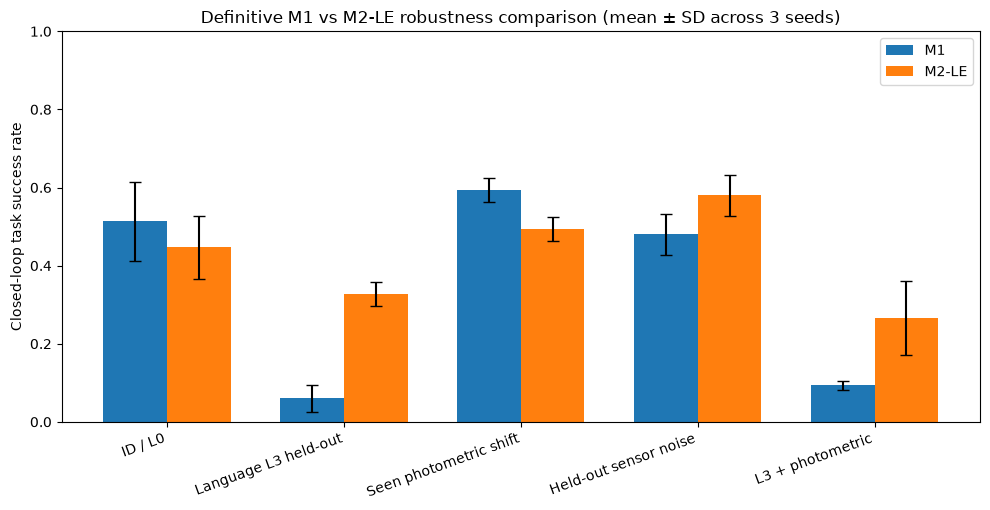

Saved: /home/leeming/projects/deep-learning-vla-robustness/results/figures/definitive_robustness_evaluation/definitive_primary_m1_vs_m2le.png


In [22]:
condition_order = (
    PRIMARY_CONDITIONS
)

condition_labels = [
    CONDITIONS[
        condition
    ][
        "label"
    ]
    for condition in (
        condition_order
    )
]


fig, ax = plt.subplots(
    figsize=(
        10,
        5.2,
    )
)


x = np.arange(
    len(
        condition_order
    )
)

width = 0.36


for offset_index, variant in enumerate(
    PRIMARY_VARIANTS
):
    variant_df = (
        primary_multiseed_summary_df[
            primary_multiseed_summary_df[
                "variant"
            ]
            == variant
        ]
        .set_index(
            "condition_id"
        )
        .reindex(
            condition_order
        )
    )

    offset = (
        (
            offset_index
            - 0.5
        )
        * width
    )

    ax.bar(
        x
        + offset,
        variant_df[
            "mean_success_rate"
        ].to_numpy(),
        width=width,
        yerr=variant_df[
            "sd_across_seeds"
        ].fillna(
            0.0
        ).to_numpy(),
        capsize=4,
        label=variant,
    )


ax.set_xticks(
    x
)

ax.set_xticklabels(
    condition_labels,
    rotation=20,
    ha="right",
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_ylabel(
    "Closed-loop task success rate"
)

ax.set_title(
    "Definitive M1 vs M2-LE robustness comparison (mean ± SD across 3 seeds)"
)

ax.legend()

fig.tight_layout()


primary_figure_path = (
    FIGURES_DIR
    / "definitive_primary_m1_vs_m2le.png"
)

fig.savefig(
    primary_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    primary_figure_path,
)

## 25. Primary paired effect-size uncertainty figure

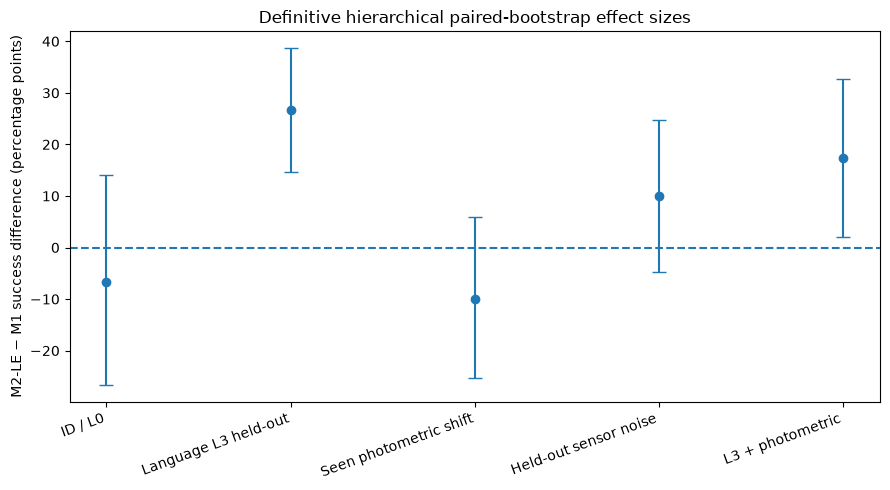

Saved: /home/leeming/projects/deep-learning-vla-robustness/results/figures/definitive_robustness_evaluation/definitive_primary_paired_effect_ci.png


In [23]:
effect_plot_df = (
    primary_effect_df
    .set_index(
        "condition_id"
    )
    .reindex(
        PRIMARY_CONDITIONS
    )
    .reset_index()
)


x = np.arange(
    len(
        effect_plot_df
    )
)

central = (
    effect_plot_df[
        "observed_delta_pp"
    ].to_numpy()
)

lower_error = (
    central
    - effect_plot_df[
        "bootstrap_95_lower_pp"
    ].to_numpy()
)

upper_error = (
    effect_plot_df[
        "bootstrap_95_upper_pp"
    ].to_numpy()
    - central
)


fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


ax.errorbar(
    x,
    central,
    yerr=np.vstack(
        [
            lower_error,
            upper_error,
        ]
    ),
    fmt="o",
    capsize=5,
)


ax.axhline(
    0.0,
    linestyle="--",
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    [
        CONDITIONS[
            condition_id
        ][
            "label"
        ]
        for condition_id in (
            effect_plot_df[
                "condition_id"
            ]
        )
    ],
    rotation=20,
    ha="right",
)

ax.set_ylabel(
    "M2-LE − M1 success difference (percentage points)"
)

ax.set_title(
    "Definitive hierarchical paired-bootstrap effect sizes"
)

fig.tight_layout()


effect_figure_path = (
    FIGURES_DIR
    / "definitive_primary_paired_effect_ci.png"
)

fig.savefig(
    effect_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    effect_figure_path,
)

## 26. Language-robustness figure

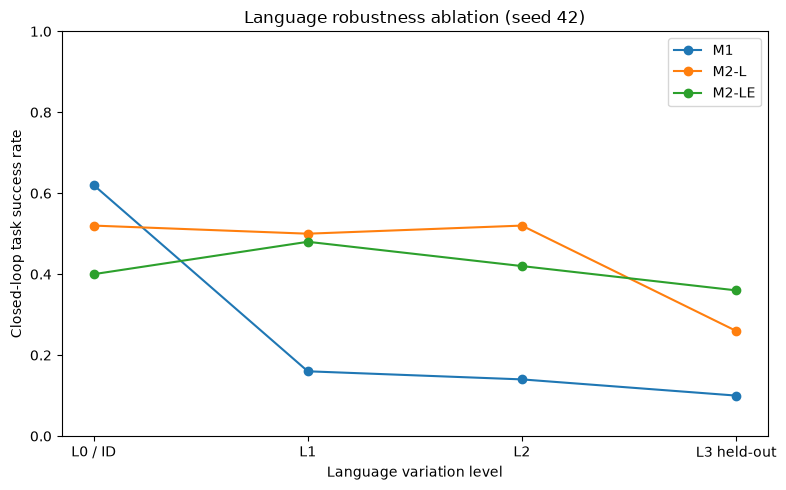

Saved: /home/leeming/projects/deep-learning-vla-robustness/results/figures/definitive_robustness_evaluation/definitive_language_ablation_seed42.png


In [24]:
fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)


language_x = np.arange(
    len(
        language_conditions
    )
)


for variant in [
    "M1",
    "M2-L",
    "M2-LE",
]:
    frame = (
        language_seed42_df[
            language_seed42_df[
                "variant"
            ]
            == variant
        ]
        .set_index(
            "condition_id"
        )
        .reindex(
            language_conditions
        )
    )

    ax.plot(
        language_x,
        frame[
            "success_rate"
        ].to_numpy(),
        marker="o",
        label=variant,
    )


ax.set_xticks(
    language_x
)

ax.set_xticklabels(
    [
        "L0 / ID",
        "L1",
        "L2",
        "L3 held-out",
    ]
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_xlabel(
    "Language variation level"
)

ax.set_ylabel(
    "Closed-loop task success rate"
)

ax.set_title(
    "Language robustness ablation (seed 42)"
)

ax.legend()

fig.tight_layout()


language_figure_path = (
    FIGURES_DIR
    / "definitive_language_ablation_seed42.png"
)

fig.savefig(
    language_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    language_figure_path,
)

## 27. Environmental-robustness figure

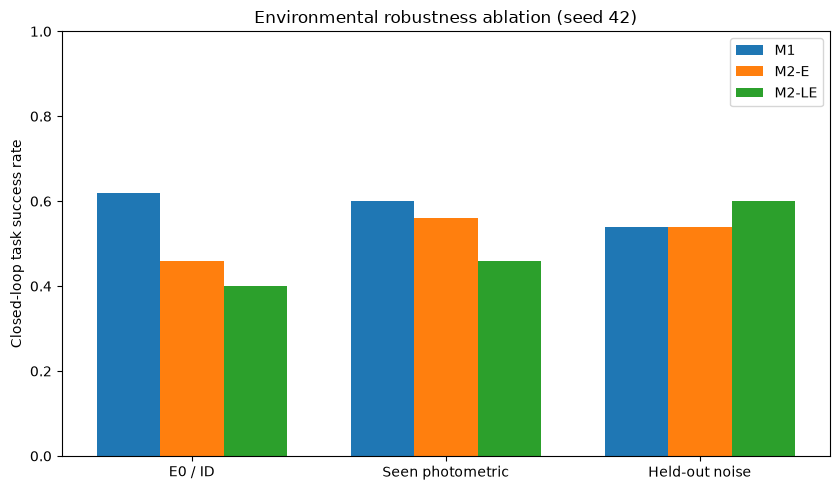

Saved: /home/leeming/projects/deep-learning-vla-robustness/results/figures/definitive_robustness_evaluation/definitive_environment_ablation_seed42.png


In [25]:
fig, ax = plt.subplots(
    figsize=(
        8.5,
        5,
    )
)


environment_x = np.arange(
    len(
        environment_conditions
    )
)

width = 0.25


for index, variant in enumerate(
    [
        "M1",
        "M2-E",
        "M2-LE",
    ]
):
    frame = (
        environment_seed42_df[
            environment_seed42_df[
                "variant"
            ]
            == variant
        ]
        .set_index(
            "condition_id"
        )
        .reindex(
            environment_conditions
        )
    )

    ax.bar(
        environment_x
        + (
            index
            - 1
        )
        * width,
        frame[
            "success_rate"
        ].to_numpy(),
        width=width,
        label=variant,
    )


ax.set_xticks(
    environment_x
)

ax.set_xticklabels(
    [
        "E0 / ID",
        "Seen photometric",
        "Held-out noise",
    ]
)

ax.set_ylim(
    0.0,
    1.0,
)

ax.set_ylabel(
    "Closed-loop task success rate"
)

ax.set_title(
    "Environmental robustness ablation (seed 42)"
)

ax.legend()

fig.tight_layout()


environment_figure_path = (
    FIGURES_DIR
    / "definitive_environment_ablation_seed42.png"
)

fig.savefig(
    environment_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    environment_figure_path,
)

## 28. Per-task primary heatmaps

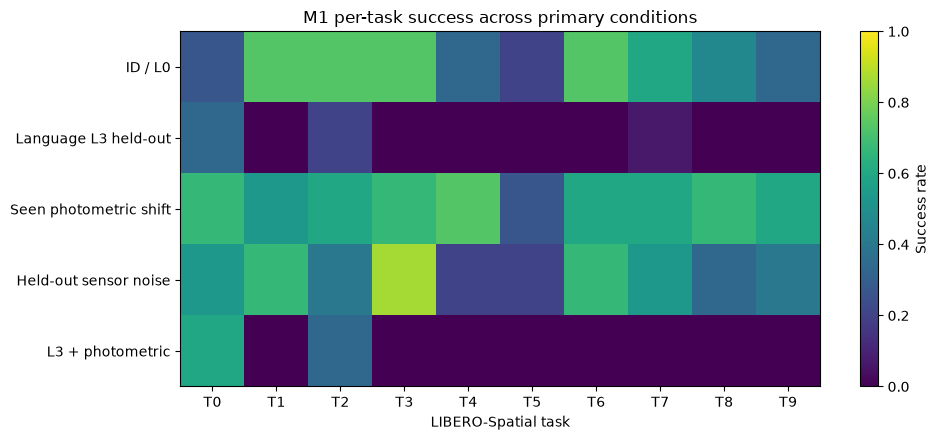

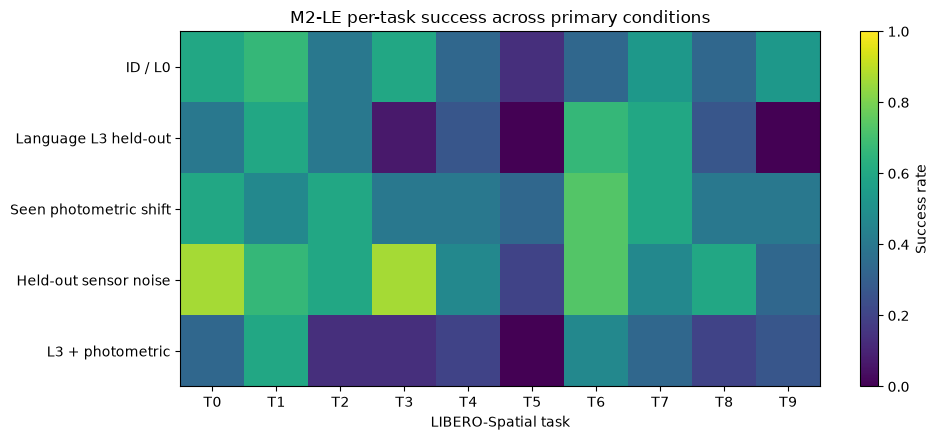

PRIMARY PER-TASK HEATMAPS: PASS


In [26]:
primary_task_summary_df = (
    episode_results_df[
        episode_results_df[
            "variant"
        ].isin(
            PRIMARY_VARIANTS
        )
        & episode_results_df[
            "model_seed"
        ].isin(
            PRIMARY_SEEDS
        )
        & episode_results_df[
            "condition_id"
        ].isin(
            PRIMARY_CONDITIONS
        )
    ]
    .groupby(
        [
            "variant",
            "condition_id",
            "suite_task_id",
        ],
        as_index=False,
    )
    .agg(
        success_rate=(
            "success",
            "mean",
        ),
        episodes=(
            "success",
            "size",
        ),
    )
)


for variant in (
    PRIMARY_VARIANTS
):
    pivot = (
        primary_task_summary_df[
            primary_task_summary_df[
                "variant"
            ]
            == variant
        ]
        .pivot(
            index="condition_id",
            columns="suite_task_id",
            values="success_rate",
        )
        .reindex(
            PRIMARY_CONDITIONS
        )
    )

    fig, ax = plt.subplots(
        figsize=(
            10,
            4.5,
        )
    )

    image = ax.imshow(
        pivot.to_numpy(),
        aspect="auto",
        vmin=0.0,
        vmax=1.0,
    )

    ax.set_xticks(
        np.arange(
            10
        )
    )

    ax.set_xticklabels(
        [
            f"T{task_id}"
            for task_id in range(
                10
            )
        ]
    )

    ax.set_yticks(
        np.arange(
            len(
                PRIMARY_CONDITIONS
            )
        )
    )

    ax.set_yticklabels(
        [
            CONDITIONS[
                condition
            ][
                "label"
            ]
            for condition in (
                PRIMARY_CONDITIONS
            )
        ]
    )

    ax.set_xlabel(
        "LIBERO-Spatial task"
    )

    ax.set_title(
        f"{variant} per-task success across primary conditions"
    )

    fig.colorbar(
        image,
        ax=ax,
        label="Success rate",
    )

    fig.tight_layout()

    figure_path = (
        FIGURES_DIR
        / (
            f"definitive_{variant.replace('-', '').lower()}"
            "_task_heatmap.png"
        )
    )

    fig.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


primary_task_summary_df.to_csv(
    METRICS_DIR
    / "primary_per_task_success.csv",
    index=False,
)

print("PRIMARY PER-TASK HEATMAPS: PASS")

## 29. Completion efficiency and inference-latency audit

In [27]:
efficiency_summary_df = (
    episode_results_df
    .groupby(
        [
            "variant",
            "model_seed",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        success_rate=(
            "success",
            "mean",
        ),
        mean_steps=(
            "steps_executed",
            "mean",
        ),
        median_steps=(
            "steps_executed",
            "median",
        ),
        mean_wall_seconds=(
            "wall_seconds",
            "mean",
        ),
        mean_select_action_seconds=(
            "mean_select_action_seconds",
            "mean",
        ),
        mean_simulator_step_seconds=(
            "mean_simulator_step_seconds",
            "mean",
        ),
    )
)


display(
    efficiency_summary_df.sort_values(
        [
            "variant",
            "model_seed",
            "condition_id",
        ]
    )
)


efficiency_summary_df.to_csv(
    METRICS_DIR
    / "completion_and_latency_summary.csv",
    index=False,
)


successful_efficiency_df = (
    episode_results_df[
        episode_results_df[
            "success"
        ]
    ]
    .groupby(
        [
            "variant",
            "model_seed",
            "condition_id",
        ],
        as_index=False,
    )
    .agg(
        successful_episodes=(
            "success",
            "size",
        ),
        mean_success_steps=(
            "steps_executed",
            "mean",
        ),
        median_success_steps=(
            "steps_executed",
            "median",
        ),
    )
)


successful_efficiency_df.to_csv(
    METRICS_DIR
    / "successful_episode_efficiency.csv",
    index=False,
)

print("COMPLETION + LATENCY AUDIT: PASS")

,variant,model_seed,condition_id,success_rate,mean_steps,median_steps,mean_wall_seconds,mean_select_action_seconds,mean_simulator_step_seconds
0,M1,42,E0_ID,0.62,174.24,116.5,11.818513,0.005171,0.060970
1,M1,42,E1_L1,0.16,250.58,280.0,16.920360,0.004927,0.060712
2,M1,42,E1_L2,0.14,253.72,280.0,17.110555,0.004829,0.060667
3,M1,42,E1_L3,0.10,260.90,280.0,17.570135,0.004843,0.060553
4,M1,42,E2_SEEN_PHOTO,0.60,179.16,132.0,12.237913,0.005104,0.060859
5,M1,42,E3_HELDOUT_NOISE,0.54,185.60,126.0,12.767871,0.005115,0.060825
6,M1,42,E4_COMBINED,0.10,259.84,280.0,17.763319,0.004928,0.060873
7,M1,123,E0_ID,0.42,205.76,280.0,14.237379,0.005066,0.062301
8,M1,123,E1_L3,0.04,272.34,280.0,18.659522,0.004830,0.061688
9,M1,123,E2_SEEN_PHOTO,0.62,170.70,120.5,11.845627,0.005119,0.061842


COMPLETION + LATENCY AUDIT: PASS


## 30. Failure-proxy analysis and manual-review template

In [28]:
failure_proxy_summary_df = (
    episode_results_df
    .groupby(
        [
            "variant",
            "condition_id",
            "failure_proxy",
        ],
        as_index=False,
    )
    .agg(
        episodes=(
            "failure_proxy",
            "size",
        )
    )
)


failure_proxy_summary_df[
    "share_within_variant_condition"
] = (
    failure_proxy_summary_df[
        "episodes"
    ]
    / failure_proxy_summary_df.groupby(
        [
            "variant",
            "condition_id",
        ]
    )[
        "episodes"
    ].transform(
        "sum"
    )
)


display(
    failure_proxy_summary_df
)


failure_proxy_summary_df.to_csv(
    METRICS_DIR
    / "failure_proxy_summary.csv",
    index=False,
)


failed_episode_df = (
    episode_results_df[
        ~episode_results_df[
            "success"
        ]
    ]
    .copy()
)


failure_review_sample_df = (
    failed_episode_df
    .sort_values(
        [
            "variant",
            "condition_id",
            "model_seed",
            "suite_task_id",
            "replica",
        ]
    )
    .groupby(
        [
            "variant",
            "condition_id",
        ],
        group_keys=False,
    )
    .head(
        3
    )
    .copy()
)


failure_review_sample_df[
    "manual_failure_code"
] = ""

failure_review_sample_df[
    "manual_failure_notes"
] = ""

failure_review_sample_df[
    "manual_review_status"
] = "NOT_REVIEWED"


failure_review_path = (
    METRICS_DIR
    / "failure_manual_review_template.csv"
)


failure_review_sample_df[
    [
        "run_id",
        "variant",
        "model_seed",
        "condition_id",
        "suite_task_id",
        "replica",
        "episode_seed",
        "failure_proxy",
        "steps_executed",
        "instruction",
        "manual_failure_code",
        "manual_failure_notes",
        "manual_review_status",
    ]
].to_csv(
    failure_review_path,
    index=False,
)


print(
    "Failure review template:",
    failure_review_path,
)

print(
    "Proxy failure categories are descriptive only; "
    "they do not replace trajectory-level manual diagnosis."
)

print("FAILURE ANALYSIS OUTPUTS: PASS")

,variant,condition_id,failure_proxy,episodes,share_within_variant_condition
0,M1,E0_ID,SUCCESS,77,0.513333
1,M1,E0_ID,TIMEOUT,73,0.486667
2,M1,E1_L1,SUCCESS,8,0.160000
3,M1,E1_L1,TIMEOUT,42,0.840000
4,M1,E1_L2,SUCCESS,7,0.140000
5,M1,E1_L2,TIMEOUT,43,0.860000
6,M1,E1_L3,SUCCESS,9,0.060000
7,M1,E1_L3,TIMEOUT,141,0.940000
8,M1,E2_SEEN_PHOTO,SUCCESS,89,0.593333
9,M1,E2_SEEN_PHOTO,TIMEOUT,61,0.406667


Failure review template: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/definitive_robustness_evaluation/failure_manual_review_template.csv
Proxy failure categories are descriptive only; they do not replace trajectory-level manual diagnosis.
FAILURE ANALYSIS OUTPUTS: PASS


## 31. ID–robustness trade-off analysis

In [29]:
id_tradeoff_rows = []


for model_seed in (
    PRIMARY_SEEDS
):
    m1_id = float(
        primary_seed_condition_df[
            (
                primary_seed_condition_df[
                    "variant"
                ]
                == "M1"
            )
            & (
                primary_seed_condition_df[
                    "model_seed"
                ]
                == model_seed
            )
            & (
                primary_seed_condition_df[
                    "condition_id"
                ]
                == "E0_ID"
            )
        ][
            "success_rate"
        ].iloc[
            0
        ]
    )

    m2le_id = float(
        primary_seed_condition_df[
            (
                primary_seed_condition_df[
                    "variant"
                ]
                == "M2-LE"
            )
            & (
                primary_seed_condition_df[
                    "model_seed"
                ]
                == model_seed
            )
            & (
                primary_seed_condition_df[
                    "condition_id"
                ]
                == "E0_ID"
            )
        ][
            "success_rate"
        ].iloc[
            0
        ]
    )

    id_tradeoff_rows.append({
        "model_seed": int(
            model_seed
        ),
        "m1_id_success": (
            m1_id
        ),
        "m2le_id_success": (
            m2le_id
        ),
        "m2le_minus_m1_id": (
            m2le_id
            - m1_id
        ),
    })


id_tradeoff_df = (
    pd.DataFrame(
        id_tradeoff_rows
    )
)


id_tradeoff_summary = {
    "mean_m1_id_success": float(
        id_tradeoff_df[
            "m1_id_success"
        ].mean()
    ),
    "mean_m2le_id_success": float(
        id_tradeoff_df[
            "m2le_id_success"
        ].mean()
    ),
    "mean_id_delta_m2le_minus_m1": float(
        id_tradeoff_df[
            "m2le_minus_m1_id"
        ].mean()
    ),
    "sd_id_delta": float(
        id_tradeoff_df[
            "m2le_minus_m1_id"
        ].std()
    ),
}


display(
    id_tradeoff_df
)

display(
    pd.DataFrame(
        [
            id_tradeoff_summary
        ]
    ).T.rename(
        columns={
            0: "Value"
        }
    )
)


id_tradeoff_df.to_csv(
    METRICS_DIR
    / "id_tradeoff_by_seed.csv",
    index=False,
)

print("ID–ROBUSTNESS TRADE-OFF ANALYSIS: PASS")

,model_seed,m1_id_success,m2le_id_success,m2le_minus_m1_id
0,42,0.62,0.40,-0.22
1,123,0.42,0.54,0.12
2,2026,0.50,0.40,-0.10


,Value
mean_m1_id_success,0.513333
mean_m2le_id_success,0.446667
mean_id_delta_m2le_minus_m1,-0.066667
sd_id_delta,0.172434


ID–ROBUSTNESS TRADE-OFF ANALYSIS: PASS


## 32. Research-question evidence table

In [30]:
def primary_mean(
    variant,
    condition_id,
):
    return float(
        primary_multiseed_summary_df[
            (
                primary_multiseed_summary_df[
                    "variant"
                ]
                == variant
            )
            & (
                primary_multiseed_summary_df[
                    "condition_id"
                ]
                == condition_id
            )
        ][
            "mean_success_rate"
        ].iloc[
            0
        ]
    )


def effect_row(
    condition_id,
):
    matches = (
        primary_effect_df[
            primary_effect_df[
                "condition_id"
            ]
            == condition_id
        ]
    )

    assert len(
        matches
    ) == 1

    return matches.iloc[
        0
    ]


l3_effect = effect_row(
    "E1_L3"
)

photo_effect = effect_row(
    "E2_SEEN_PHOTO"
)

noise_effect = effect_row(
    "E3_HELDOUT_NOISE"
)

combined_effect = effect_row(
    "E4_COMBINED"
)

id_effect = effect_row(
    "E0_ID"
)


rq_rows = [
    {
        "research_question": "RQ1",
        "question": (
            "Does robustness-oriented fine-tuning improve "
            "closed-loop success under distribution shift?"
        ),
        "primary_evidence": (
            "M2-LE−M1 paired effects: "
            f"L3={l3_effect['observed_delta_pp']:+.1f} pp, "
            f"photo={photo_effect['observed_delta_pp']:+.1f} pp, "
            f"noise={noise_effect['observed_delta_pp']:+.1f} pp, "
            f"combined={combined_effect['observed_delta_pp']:+.1f} pp."
        ),
        "evidence_class": (
            "/".join(
                [
                    str(
                        l3_effect[
                            "evidence_class"
                        ]
                    ),
                    str(
                        photo_effect[
                            "evidence_class"
                        ]
                    ),
                    str(
                        noise_effect[
                            "evidence_class"
                        ]
                    ),
                    str(
                        combined_effect[
                            "evidence_class"
                        ]
                    ),
                ]
            )
        ),
    },
    {
        "research_question": "RQ2",
        "question": (
            "How does language variation affect SmolVLA and "
            "does language-aware training help?"
        ),
        "primary_evidence": (
            "Seed-42 L0/L1/L2/L3 curves compare M1, M2-L and M2-LE; "
            f"multi-seed held-out L3 effect={l3_effect['observed_delta_pp']:+.1f} pp."
        ),
        "evidence_class": str(
            l3_effect[
                "evidence_class"
            ]
        ),
    },
    {
        "research_question": "RQ3",
        "question": (
            "Which evaluated environmental perturbations cause "
            "the strongest degradation?"
        ),
        "primary_evidence": (
            "Primary generalization gaps quantify photometric and "
            "held-out sensor-noise degradation for M1 and M2-LE."
        ),
        "evidence_class": (
            "DESCRIPTIVE_COMPARISON"
        ),
    },
    {
        "research_question": "RQ4",
        "question": (
            "Does robustness training transfer to held-out perturbation categories?"
        ),
        "primary_evidence": (
            f"Held-out L3 effect={l3_effect['observed_delta_pp']:+.1f} pp; "
            f"held-out noise effect={noise_effect['observed_delta_pp']:+.1f} pp."
        ),
        "evidence_class": (
            f"L3:{l3_effect['evidence_class']} | "
            f"NOISE:{noise_effect['evidence_class']}"
        ),
    },
    {
        "research_question": "RQ5",
        "question": (
            "Is robustness associated with an ID-performance trade-off?"
        ),
        "primary_evidence": (
            f"ID M2-LE−M1 paired effect={id_effect['observed_delta_pp']:+.1f} pp; "
            f"M1 mean ID={primary_mean('M1','E0_ID'):.3f}, "
            f"M2-LE mean ID={primary_mean('M2-LE','E0_ID'):.3f}."
        ),
        "evidence_class": str(
            id_effect[
                "evidence_class"
            ]
        ),
    },
]


rq_evidence_df = pd.DataFrame(
    rq_rows
)


display(
    rq_evidence_df
)


rq_evidence_df.to_csv(
    METRICS_DIR
    / "research_question_evidence.csv",
    index=False,
)

assert len(
    rq_evidence_df
) == 5

print("RESEARCH-QUESTION EVIDENCE TABLE: PASS")

,research_question,question,primary_evidence,evidence_class
0,RQ1,Does robustness-oriented fine-tuning improve c...,"M2-LE−M1 paired effects: L3=+26.7 pp, photo=-1...",STRONG_MULTI_SEED_SUPPORT/DIRECTIONAL_EVIDENCE...
1,RQ2,How does language variation affect SmolVLA and...,"Seed-42 L0/L1/L2/L3 curves compare M1, M2-L an...",STRONG_MULTI_SEED_SUPPORT
2,RQ3,Which evaluated environmental perturbations ca...,Primary generalization gaps quantify photometr...,DESCRIPTIVE_COMPARISON
3,RQ4,Does robustness training transfer to held-out ...,Held-out L3 effect=+26.7 pp; held-out noise ef...,L3:STRONG_MULTI_SEED_SUPPORT | NOISE:DIRECTION...
4,RQ5,Is robustness associated with an ID-performanc...,ID M2-LE−M1 paired effect=-6.7 pp; M1 mean ID=...,DIRECTIONAL_EVIDENCE_AGAINST


RESEARCH-QUESTION EVIDENCE TABLE: PASS


## 33. Definitive headline result table

In [31]:
headline_rows = []


for condition_id in (
    PRIMARY_CONDITIONS
):
    m1 = (
        primary_multiseed_summary_df[
            (
                primary_multiseed_summary_df[
                    "variant"
                ]
                == "M1"
            )
            & (
                primary_multiseed_summary_df[
                    "condition_id"
                ]
                == condition_id
            )
        ].iloc[
            0
        ]
    )

    m2le = (
        primary_multiseed_summary_df[
            (
                primary_multiseed_summary_df[
                    "variant"
                ]
                == "M2-LE"
            )
            & (
                primary_multiseed_summary_df[
                    "condition_id"
                ]
                == condition_id
            )
        ].iloc[
            0
        ]
    )

    effect = (
        effect_row(
            condition_id
        )
    )

    headline_rows.append({
        "condition_id": (
            condition_id
        ),
        "condition_label": (
            CONDITIONS[
                condition_id
            ][
                "label"
            ]
        ),
        "m1_mean_success": float(
            m1[
                "mean_success_rate"
            ]
        ),
        "m1_sd_across_seeds": float(
            m1[
                "sd_across_seeds"
            ]
        ),
        "m2le_mean_success": float(
            m2le[
                "mean_success_rate"
            ]
        ),
        "m2le_sd_across_seeds": float(
            m2le[
                "sd_across_seeds"
            ]
        ),
        "paired_delta_pp": float(
            effect[
                "observed_delta_pp"
            ]
        ),
        "paired_bootstrap_95_lower_pp": float(
            effect[
                "bootstrap_95_lower_pp"
            ]
        ),
        "paired_bootstrap_95_upper_pp": float(
            effect[
                "bootstrap_95_upper_pp"
            ]
        ),
        "holm_adjusted_mcnemar_p": float(
            effect[
                "holm_adjusted_p_value"
            ]
        ),
        "improved_seeds": int(
            effect[
                "improved_seeds"
            ]
        ),
        "evidence_class": str(
            effect[
                "evidence_class"
            ]
        ),
    })


headline_result_df = (
    pd.DataFrame(
        headline_rows
    )
)


display(
    headline_result_df
)


headline_result_path = (
    METRICS_DIR
    / "definitive_headline_results.csv"
)


headline_result_df.to_csv(
    headline_result_path,
    index=False,
)

print(
    "Definitive headline results:",
    headline_result_path,
)

,condition_id,condition_label,m1_mean_success,m1_sd_across_seeds,m2le_mean_success,m2le_sd_across_seeds,paired_delta_pp,paired_bootstrap_95_lower_pp,paired_bootstrap_95_upper_pp,holm_adjusted_mcnemar_p,improved_seeds,evidence_class
0,E0_ID,ID / L0,0.513333,0.100664,0.446667,0.080829,-6.666667,-26.666667,14.000000,2.593117e-01,1,DIRECTIONAL_EVIDENCE_AGAINST
1,E1_L3,Language L3 held-out,0.060000,0.034641,0.326667,0.030551,26.666667,14.666667,38.666667,7.569163e-09,3,STRONG_MULTI_SEED_SUPPORT
2,E2_SEEN_PHOTO,Seen photometric shift,0.593333,0.030551,0.493333,0.030551,-10.000000,-25.333333,6.000000,2.593117e-01,0,DIRECTIONAL_EVIDENCE_AGAINST
3,E3_HELDOUT_NOISE,Held-out sensor noise,0.480000,0.052915,0.580000,0.052915,10.000000,-4.666667,24.666667,2.593117e-01,3,DIRECTIONAL_SUPPORT
4,E4_COMBINED,L3 + photometric,0.093333,0.011547,0.266667,0.094516,17.333333,2.000000,32.666667,6.256688e-04,3,STRONG_MULTI_SEED_SUPPORT


Definitive headline results: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/definitive_robustness_evaluation/definitive_headline_results.csv


## 34. Final reproducibility and technical status

In [32]:
final_checks = {
    "Notebook 06 prerequisite":
        (
            notebook06_summary[
                "technical_status"
            ]
            == "PASS"
        ),

    "Eight frozen checkpoints":
        (
            len(
                model_registry_df
            )
            == 8
        ),

    "No post-OOD checkpoint selection":
        (
            evaluation_handoff[
                "model_selection_after_ood_forbidden"
            ]
            is True
        ),

    "Definitive protocol frozen":
        (
            EVALUATION_PROTOCOL_PATH.exists()
        ),

    "2050 planned episodes":
        (
            PLANNED_EPISODES
            == 2050
        ),

    "2050 completed episodes":
        (
            COMPLETED_EPISODES
            == 2050
        ),

    "Zero missing episodes":
        (
            MISSING_EPISODES
            == 0
        ),

    "All system statuses PASS":
        bool(
            (
                episode_results_df[
                    "system_status"
                ]
                == "PASS"
            ).all()
        ),

    "Condition summaries complete":
        (
            len(
                condition_summary_df
            )
            == len(
                evaluation_plan_df
            )
        ),

    "Per-seed bootstrap complete":
        (
            len(
                per_seed_bootstrap_df
            )
            == len(
                evaluation_plan_df
            )
        ),

    "Primary multi-seed matrix complete":
        (
            len(
                primary_seed_condition_df
            )
            == (
                len(
                    PRIMARY_VARIANTS
                )
                * len(
                    PRIMARY_SEEDS
                )
                * len(
                    PRIMARY_CONDITIONS
                )
            )
        ),

    "Primary paired effects complete":
        (
            len(
                primary_effect_df
            )
            == len(
                PRIMARY_CONDITIONS
            )
        ),

    "Holm-adjusted paired tests complete":
        (
            len(
                primary_mcnemar_df
            )
            == len(
                PRIMARY_CONDITIONS
            )
        ),

    "Generalization gaps complete":
        (
            not generalization_gap_df.empty
        ),

    "Language ablation complete":
        (
            len(
                language_seed42_df
            )
            == 12
        ),

    "Environmental ablation complete":
        (
            len(
                environment_seed42_df
            )
            == 9
        ),

    "Failure analysis outputs":
        (
            (
                METRICS_DIR
                / "failure_proxy_summary.csv"
            ).exists()
            and failure_review_path.exists()
        ),

    "Research-question evidence":
        (
            len(
                rq_evidence_df
            )
            == 5
        ),

    "Headline results":
        (
            headline_result_path.exists()
        ),

    "Primary figure":
        (
            primary_figure_path.exists()
        ),

    "Paired effect figure":
        (
            effect_figure_path.exists()
        ),

    "Language figure":
        (
            language_figure_path.exists()
        ),

    "Environment figure":
        (
            environment_figure_path.exists()
        ),
}


final_checks = {
    key: bool(
        value
    )
    for key, value
    in final_checks.items()
}


status_df = pd.DataFrame(
    [
        {
            "check": key,
            "status": (
                "PASS"
                if passed
                else "FAIL"
            ),
        }
        for key, passed
        in final_checks.items()
    ]
)


display(
    status_df
)


NOTEBOOK_07_PASS = bool(
    all(
        final_checks.values()
    )
)


notebook07_summary = {
    "notebook": (
        "07_definitive_robustness_evaluation"
    ),
    "technical_status": (
        "PASS"
        if NOTEBOOK_07_PASS
        else "FAIL"
    ),
    "evaluation_protocol_sha256": (
        EVALUATION_PROTOCOL_SHA256
    ),
    "project_git_sha": (
        PROJECT_GIT_SHA
    ),
    "final_training_steps": int(
        evaluation_handoff[
            "final_training_steps"
        ]
    ),
    "final_checkpoint_count": int(
        len(
            model_registry_df
        )
    ),
    "episodes_per_task": int(
        EPISODES_PER_TASK
    ),
    "planned_episodes": int(
        PLANNED_EPISODES
    ),
    "completed_episodes": int(
        COMPLETED_EPISODES
    ),
    "primary_variants": (
        PRIMARY_VARIANTS
    ),
    "primary_seeds": (
        PRIMARY_SEEDS
    ),
    "primary_conditions": (
        PRIMARY_CONDITIONS
    ),
    "selection_used_ood_results": False,
    "post_ood_model_replacement": False,
    "headline_results": str(
        headline_result_path.relative_to(
            REPO_ROOT
        )
    ),
    "research_question_evidence": str(
        (
            METRICS_DIR
            / "research_question_evidence.csv"
        ).relative_to(
            REPO_ROOT
        )
    ),
    "technical_checks": (
        final_checks
    ),
}


notebook07_summary_path = (
    METRICS_DIR
    / "notebook07_summary.json"
)


with open(
    notebook07_summary_path,
    "w",
) as f:
    json.dump(
        notebook07_summary,
        f,
        indent=2,
    )


print(
    "="
    * 84
)

print(
    "NOTEBOOK 07 — DEFINITIVE ROBUSTNESS EVALUATION STATUS"
)

print(
    "="
    * 84
)


for key, value in (
    final_checks.items()
):
    print(
        f"{key:<66} "
        f"{'PASS' if value else 'FAIL'}"
    )


print(
    "-"
    * 84
)

print(
    f"{'NOTEBOOK 07 TECHNICAL STATUS':<66} "
    f"{'PASS' if NOTEBOOK_07_PASS else 'FAIL'}"
)

print(
    f"{'FROZEN CHECKPOINTS':<66} "
    f"{len(model_registry_df)}"
)

print(
    f"{'CLOSED-LOOP EPISODES':<66} "
    f"{COMPLETED_EPISODES}/{PLANNED_EPISODES}"
)

print(
    f"{'POST-OOD TRAINING / MODEL REPLACEMENT':<66} "
    f"NONE"
)

print(
    "-"
    * 84
)


assert NOTEBOOK_07_PASS, (
    "Notebook 07 contains an incomplete definitive evaluation artifact."
)


print()

print(
    "Definitive headline results:",
    headline_result_path,
)

print(
    "Research-question evidence:",
    METRICS_DIR
    / "research_question_evidence.csv",
)

print(
    "Summary:",
    notebook07_summary_path,
)

,check,status
0,Notebook 06 prerequisite,PASS
1,Eight frozen checkpoints,PASS
2,No post-OOD checkpoint selection,PASS
3,Definitive protocol frozen,PASS
4,2050 planned episodes,PASS
5,2050 completed episodes,PASS
6,Zero missing episodes,PASS
7,All system statuses PASS,PASS
8,Condition summaries complete,PASS
9,Per-seed bootstrap complete,PASS


NOTEBOOK 07 — DEFINITIVE ROBUSTNESS EVALUATION STATUS
Notebook 06 prerequisite                                           PASS
Eight frozen checkpoints                                           PASS
No post-OOD checkpoint selection                                   PASS
Definitive protocol frozen                                         PASS
2050 planned episodes                                              PASS
2050 completed episodes                                            PASS
Zero missing episodes                                              PASS
All system statuses PASS                                           PASS
Condition summaries complete                                       PASS
Per-seed bootstrap complete                                        PASS
Primary multi-seed matrix complete                                 PASS
Primary paired effects complete                                    PASS
Holm-adjusted paired tests complete                                PASS
Generaliza

## 35. Report-ready interpretation framework

Notebook 07 is the source of truth for final robustness claims.

### What may be claimed

The report may state that:

- all compared models used the same frozen training budget;
- final checkpoints were frozen before definitive OOD evaluation;
- M1 and M2-LE were compared at matched seeds 42/123/2026;
- each primary model-seed-condition cell used 50 closed-loop episodes;
- L3 was held out from training;
- Gaussian sensor noise was a held-out visual perturbation category;
- paired reset seeds were reused across M1 and M2-LE;
- uncertainty was quantified with hierarchical bootstrap;
- exact paired McNemar tests were Holm-adjusted across the five primary conditions;
- component ablations were evaluated separately at seed 42.

### What must not be overstated

- A positive mean difference is not automatically statistical proof.
- Single-seed M2-L/M2-E ablations are mechanism evidence, not multi-seed confirmation.
- The photometric condition tests a **seen augmentation family**, not an unseen environmental category.
- Gaussian noise is a held-out visual perturbation, but it does not represent all real-world environmental changes.
- Camera viewpoint, object layout and robot-initial-state perturbation suites remain outside the implemented evaluation scope.
- The proxy failure categories do not replace trajectory-level semantic failure annotation.

### Final interpretation rule

Use the `evidence_class` column in:

`results/metrics/definitive_robustness_evaluation/definitive_headline_results.csv`

to distinguish:

- strong multi-seed support,
- directional support,
- directional evidence against,
- no clear advantage.

Do not alter the training configuration after reading these outcomes.

## 36. Next project stage

After Notebook 07 passes, the experimental model-development cycle is closed.

The next notebook should **not train or retune models**.

Recommended next stage:

### Notebook 08 — Final Results, Assignment Evidence and Report Figures

Its role should be to:

- consolidate Notebook 05/05b budget-validation evidence,
- consolidate Notebook 06 final-training evidence,
- consolidate Notebook 07 definitive robustness evidence,
- map results explicitly to RQ1–RQ5,
- produce final tables/figures for the written report,
- separate pilot Notebook 04 from definitive Notebook 07,
- document limitations and threats to validity,
- create the final reproducibility/submission checklist.

Notebook 08 should consume frozen artifacts only.